In [1]:
import sys
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import scanpy as sc
from IPython.display import display
from metab_processing.metab_travlr_config import DATA_DIR
from metab_processing.LinearRegression import signature_helpers as sh
from metab_processing.LinearRegression.least_squares import (
    fit_gene_betas, subsample_gene_betas, rank_coefficients)

# Merged colon dataset (built once by colon_test.ipynb's REBUILD_FULL step).
FULL_DATA_PATH = f'{DATA_DIR}/Alexi_UC_Full_Data/processed_adata.h5ad'
ANNOT_COL, CELL_TYPE = '25_06_11_ICI_5K_Coarse_annotations', 'IEC'
COND_COL = '240927_Condition'              # UC / HC / ICI
PATIENT_COL = '25_06_11_Patient_ID_HS'
SAMPLE_COL = 'slice'                        # per-sample label added by merge_x_adatas
METHOD, PENALTY, STANDARDIZE = 'l1', 0.005, True
N_SUB = 50
LOWER, UPPER = 15, 85
DBVER = '2024.1.Hs'

SINGLE_GENE = 'CD3E'                         # single-gene reference, to contrast with signatures

SIGNATURES = [
    'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION',
    'HALLMARK_TNFA_SIGNALING_VIA_NFKB',
    'HALLMARK_INFLAMMATORY_RESPONSE',
    'HALLMARK_OXIDATIVE_PHOSPHORYLATION',
    'HALLMARK_GLYCOLYSIS',
    'HALLMARK_HYPOXIA',
    'HALLMARK_FATTY_ACID_METABOLISM',
    'HALLMARK_MTORC1_SIGNALING',
    'HALLMARK_APICAL_JUNCTION',
    'HALLMARK_APICAL_SURFACE',
    'HALLMARK_BILE_ACID_METABOLISM',
    'HALLMARK_XENOBIOTIC_METABOLISM',
    'GOBP_BICARBONATE_TRANSPORT',
    'GOBP_SODIUM_ION_TRANSPORT',
    'GOBP_DEFENSE_RESPONSE_TO_BACTERIUM',
    'GOBP_ANTIMICROBIAL_HUMORAL_RESPONSE',
    'HALLMARK_PANCREAS_BETA_CELLS',
    'HALLMARK_SPERMATOGENESIS',
]

In [2]:
adata = sc.read_h5ad(FULL_DATA_PATH)
var = set(adata.var_names)
print(adata.n_obs, 'cells |', len(adata.uns.get('x_genes', [])), 'built genes')
print('\nconditions:', adata.obs[COND_COL].value_counts().to_dict())

255082 cells | 4736 built genes

conditions: {'HC': 95100, 'UC': 91559, 'ICI': 68423}


In [3]:
library = sh.load_msigdb(DBVER)
print('loaded', len(library), 'gene sets')

loaded 10410 gene sets


## Target signatures: membership, missing, present, factor-removed, remaining

In [4]:
sets = sh.resolve_sets(SIGNATURES, library, var, label='colon target signatures')
sh.report_factor_removal(adata, sets)

===== colon target signatures: membership vs data (18 sets) =====

GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION  (16/28 present)
  in signature (28): ['C1GALT1', 'CBFA2T2', 'CDKN1A', 'CDX2', 'FZD5', 'GATA4', 'GATA5', 'GATA6', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'MIR29B1', 'NKX3-2', 'NPY', 'PRDM1', 'PTK6', 'PYY', 'SAV1', 'SOX9', 'SPDEF', 'SRC', 'TIGAR', 'TLR9', 'TMIGD1', 'TYMS', 'YAP1', 'YIPF6']
  missing from data (12): ['C1GALT1', 'CBFA2T2', 'FZD5', 'GATA5', 'MIR29B1', 'NKX3-2', 'NPY', 'SAV1', 'SPDEF', 'TIGAR', 'TMIGD1', 'YIPF6']
  present in data (16): ['CDKN1A', 'CDX2', 'GATA4', 'GATA6', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'PTK6', 'PYY', 'SOX9', 'SRC', 'TLR9', 'TYMS', 'YAP1']

HALLMARK_TNFA_SIGNALING_VIA_NFKB  (109/200 present)
  in signature (200): ['ABCA1', 'ACKR3', 'AREG', 'ATF3', 'ATP2B1', 'B4GALT1', 'B4GALT5', 'BCL2A1', 'BCL3', 'BCL6', 'BHLHE40', 'BIRC2', 'BIRC3', 'BMP2', 'BTG1', 'BTG2', 'BTG3', 'CCL2', 'CCL20', 'CCL4', 'CCL5', 'CCN1', 'CCND1', 'CCNL1', 'CCRL2', 'CD44

## Batch-covariate drivers

Same per-signature prediction as `signature_analysis`, but run across **sample subsets**
(all / UC / HC / ICI) and **batch covariates** (none / condition / patient / slice), each an
unpenalized one-hot (FWL) so per-batch level shifts don't leak into the factor betas.
`run_colon_gene` does the same for a single raw gene (the reference at the top).

In [5]:
def run_colon_gene(target=SINGLE_GENE, n_sub=N_SUB):
    """Single-gene reference across the same subset x covariate grid as the signatures."""
    for oh in [None, COND_COL, PATIENT_COL, SAMPLE_COL]:
        _run_gene_one(adata, target, oh, 'All colon samples', n_sub)
    for cond in ['UC', 'HC', 'ICI']:
        sub_ad = adata[adata.obs[COND_COL] == cond].copy()
        for oh in [None, PATIENT_COL, SAMPLE_COL]:
            _run_gene_one(sub_ad, target, oh, f'Only {cond} samples', n_sub)


def _run_gene_one(ad, target, onehot_col, samples_name, n_sub):
    print(f'\n===== {target} | {samples_name} | covariate={onehot_col} =====')
    try:
        b = fit_gene_betas(ad, genes=[target], annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                           metabolites=[], custom='all', method=METHOD, penalty=PENALTY,
                           standardize=STANDARDIZE, onehot_col=onehot_col)
        sub, sub_r = subsample_gene_betas(ad, target, factors=None, n_subsamples=n_sub,
                                          annot_col=ANNOT_COL, annot_value=CELL_TYPE,
                                          metabolites=[], custom='all', method=METHOD, penalty=PENALTY,
                                          standardize=STANDARDIZE, onehot_col=onehot_col, return_r=True,
                                          just_skip_samples_without_all_labels=True)
    except Exception as e:
        print(f'  run failed ({type(e).__name__}: {e})'); return
    res = sh.add_subsample_percentiles(rank_coefficients(b), sub, sub_r, LOWER, UPPER)
    display(res.head(40))
    sh.filter_and_plot_ratio(res).set_title(f'{target} | {samples_name} | covariate={onehot_col} | |avg_beta|/INTERVAL')
    sh.filter_and_plot_variance_ratio(res).set_title(f'{target} | {samples_name} | covariate={onehot_col} | |avg_beta|/VARIANCE')


def run_colon_signature(name, n_sub=N_SUB):
    """Predict signature `name` across the subset x batch-covariate grid."""
    for oh in [None, COND_COL, PATIENT_COL, SAMPLE_COL]:
        sh.run_one(adata, name, sets, annot_col=ANNOT_COL, annot_value=CELL_TYPE, onehot_col=oh,
                   samples_name='All colon samples', method=METHOD, penalty=PENALTY,
                   standardize=STANDARDIZE, n_sub=n_sub, custom='all', metabolites=[])
    for cond in ['UC', 'HC', 'ICI']:
        sub_ad = adata[adata.obs[COND_COL] == cond].copy()
        for oh in [None, PATIENT_COL, SAMPLE_COL]:
            sh.run_one(sub_ad, name, sets, annot_col=ANNOT_COL, annot_value=CELL_TYPE, onehot_col=oh,
                       samples_name=f'Only {cond} samples', method=METHOD, penalty=PENALTY,
                       standardize=STANDARDIZE, n_sub=n_sub, custom='all', metabolites=[])

## Single-gene reference: CD3E (shows the difference vs a signature target)


===== CD3E | All colon samples | covariate=None =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
563,CD3E,LCK$CD8A,lr,0.005911,0.108714,1.181863e-02,0.026357,110157,0.002418,0.009917,0.006080,2.600091e-06,2.628678e-06,0.004396,0.007765,0.073362,0.147348,0.110840
33,CD3E,STAT1,tf,0.003734,0.099680,9.936141e-03,0.026357,110157,0.001707,0.004995,0.003528,4.498135e-07,4.920028e-07,0.002892,0.004223,0.085495,0.108738,0.099122
540,CD3E,ICAM1$ITGAL,lr,0.003142,0.085974,7.391517e-03,0.026357,110157,0.000000,0.008475,0.003001,4.778891e-06,4.798899e-06,0.000562,0.005209,0.052267,0.142887,0.086267
729,CD3E,IFNG#STAT1,ltf,0.002343,0.095461,9.112879e-03,0.026357,110157,0.001153,0.004042,0.002469,5.074239e-07,5.233468e-07,0.001732,0.003393,0.080455,0.108611,0.096179
218,CD3E,IL15$IL2RB,lr,0.002181,0.072820,5.302820e-03,0.026357,110157,0.000216,0.005265,0.002119,1.098644e-06,1.102403e-06,0.000982,0.003188,0.054195,0.104547,0.072756
528,CD3E,CDH1$ITGAE,lr,0.001680,0.068812,4.735023e-03,0.026357,110157,0.000000,0.004604,0.001611,1.314107e-06,1.318785e-06,0.000125,0.002724,0.039950,0.100771,0.068712
308,CD3E,TNFSF9$TNFRSF9,lr,0.000569,0.060251,3.630220e-03,0.026357,110157,0.000000,0.002921,0.000743,6.751250e-07,7.055129e-07,0.000000,0.001666,0.035786,0.086454,0.060810
552,CD3E,F11R$ITGAL,lr,0.000372,0.066596,4.435015e-03,0.026357,110157,0.000000,0.002694,0.000848,6.608101e-07,8.878342e-07,0.000000,0.001934,0.043959,0.097184,0.068387
209,CD3E,CXCL16$CXCR6,lr,0.000338,0.057076,3.257706e-03,0.026357,110157,0.000000,0.002353,0.000539,4.373577e-07,4.777496e-07,0.000000,0.001422,0.034596,0.076286,0.056903
611,CD3E,VEGFC#ARID3B,ltf,-0.000000,0.001271,1.614672e-06,0.026357,110157,-0.000000,-0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,-0.002196,0.004905,0.001342


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.



===== CD3E | All colon samples | covariate=240927_Condition =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
912,CD3E,240927_Condition[ICI],onehot,0.017984,0.088112,7.763783e-03,0.028932,110157,0.016332,0.019224,0.017807,5.960471e-07,6.274610e-07,0.016881,0.018679,0.081237,0.092741,0.087556
563,CD3E,LCK$CD8A,lr,0.005619,0.108714,1.181863e-02,0.028932,110157,0.002141,0.009647,0.005791,2.588120e-06,2.617815e-06,0.004107,0.007488,0.073362,0.147348,0.110840
540,CD3E,ICAM1$ITGAL,lr,0.003045,0.085974,7.391517e-03,0.028932,110157,0.000000,0.008347,0.002912,4.730435e-06,4.748018e-06,0.000479,0.005129,0.052267,0.142887,0.086267
33,CD3E,STAT1,tf,0.002280,0.099680,9.936141e-03,0.028932,110157,0.000356,0.003498,0.002099,4.280441e-07,4.609978e-07,0.001428,0.002849,0.085495,0.108738,0.099122
218,CD3E,IL15$IL2RB,lr,0.002186,0.072820,5.302820e-03,0.028932,110157,0.000208,0.005300,0.002124,1.107706e-06,1.111539e-06,0.000952,0.003209,0.054195,0.104547,0.072756
528,CD3E,CDH1$ITGAE,lr,0.001591,0.068812,4.735023e-03,0.028932,110157,0.000000,0.004520,0.001538,1.278210e-06,1.281022e-06,0.000022,0.002674,0.039950,0.100771,0.068712
729,CD3E,IFNG#STAT1,ltf,0.001315,0.095461,9.112879e-03,0.028932,110157,0.000169,0.002986,0.001452,4.998715e-07,5.185927e-07,0.000726,0.002365,0.080455,0.108611,0.096179
913,CD3E,240927_Condition[UC],onehot,0.000967,-0.033989,1.155250e-03,0.028932,110157,-0.000380,0.002599,0.000944,3.959922e-07,3.965536e-07,0.000350,0.001496,-0.039402,-0.026810,-0.033835
308,CD3E,TNFSF9$TNFRSF9,lr,0.000552,0.060251,3.630220e-03,0.028932,110157,0.000000,0.002912,0.000729,6.654890e-07,6.969192e-07,0.000000,0.001630,0.035786,0.086454,0.060810
552,CD3E,F11R$ITGAL,lr,0.000380,0.066596,4.435015e-03,0.028932,110157,0.000000,0.002753,0.000855,6.763341e-07,9.018010e-07,0.000000,0.001940,0.043959,0.097184,0.068387


...

/global/home/users/fosterangus/Projects/MetabTravLR/SpaceTravLR/metab_processing/LinearRegression/signature_helpers.py:180: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  _, ax = plt.subplots(figsize=figsize)



===== CD3E | Only ICI samples | covariate=25_06_11_Patient_ID_HS =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
912,CD3E,25_06_11_Patient_ID_HS[13674_HS9_ICI],onehot,0.040758,0.153469,0.023553,0.078925,32759,0.035636,0.044727,0.040306,3.746706e-06,3.950786e-06,0.038556,0.042309,0.145462,0.162155,0.152928
563,CD3E,LCK$CD8A,lr,0.011759,0.136673,0.018680,0.078925,32759,0.004907,0.017126,0.010722,7.479563e-06,8.554520e-06,0.008575,0.013678,0.083229,0.187086,0.134787
540,CD3E,ICAM1$ITGAL,lr,0.008982,0.117573,0.013823,0.078925,32759,0.001405,0.018051,0.008208,1.398671e-05,1.458516e-05,0.003628,0.012106,0.069566,0.183934,0.118448
308,CD3E,TNFSF9$TNFRSF9,lr,0.005810,0.103362,0.010684,0.078925,32759,0.000000,0.010504,0.005118,4.891048e-06,5.369188e-06,0.002837,0.007407,0.059951,0.147420,0.105295
528,CD3E,CDH1$ITGAE,lr,0.005519,0.080761,0.006522,0.078925,32759,0.001259,0.008989,0.004943,3.156000e-06,3.486930e-06,0.003220,0.006363,0.053469,0.113650,0.080306
209,CD3E,CXCL16$CXCR6,lr,0.004792,0.086406,0.007466,0.078925,32759,0.000000,0.008991,0.004339,4.722526e-06,4.927325e-06,0.002191,0.006683,0.047823,0.119947,0.084204
574,CD3E,NECTIN3$TIGIT,lr,0.004155,0.071167,0.005065,0.078925,32759,0.000000,0.010395,0.003817,7.947151e-06,8.061178e-06,0.000695,0.007068,0.041208,0.120115,0.070378
766,CD3E,CXCL10$CXCR3,lr,0.003286,0.072316,0.005230,0.078925,32759,0.000000,0.008816,0.002449,4.239589e-06,4.941527e-06,0.000000,0.004766,0.041828,0.109373,0.070721
505,CD3E,ALCAM$CD6,lr,0.003113,0.072249,0.005220,0.078925,32759,0.000000,0.009536,0.002935,6.576462e-06,6.607986e-06,0.000038,0.005796,0.025667,0.123763,0.071721
218,CD3E,IL15$IL2RB,lr,0.002838,0.072635,0.005276,0.078925,32759,0.000000,0.007923,0.002893,3.973049e-06,3.976147e-06,0.000801,0.005424,0.042694,0.111807,0.076593



===== CD3E | Only ICI samples | covariate=slice =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
916,CD3E,slice[13674_HS9_ICI-Slice_2],onehot,0.047292,0.092114,0.008485,0.079006,32759,0.041213,0.052137,0.046133,7.763448e-06,9.104699e-06,0.043349,0.049596,0.075562,0.102288,0.089798
915,CD3E,slice[13674_HS9_ICI-Slice_1],onehot,0.041904,0.089716,0.008049,0.079006,32759,0.034398,0.050392,0.041531,1.041030e-05,1.054892e-05,0.038337,0.044285,0.077153,0.110910,0.091345
563,CD3E,LCK$CD8A,lr,0.011778,0.136673,0.018680,0.079006,32759,0.004943,0.017128,0.010745,7.453966e-06,8.521752e-06,0.008601,0.013695,0.083229,0.187086,0.134787
914,CD3E,slice[12362_HS7_ICI-Slice_4],onehot,0.009746,-0.017855,0.000319,0.079006,32759,0.000432,0.014907,0.008359,1.093958e-05,1.286253e-05,0.005106,0.011743,-0.026516,-0.007701,-0.017728
540,CD3E,ICAM1$ITGAL,lr,0.009033,0.117573,0.013823,0.079006,32759,0.001438,0.018093,0.008252,1.400302e-05,1.461166e-05,0.003694,0.012143,0.069566,0.183934,0.118448
308,CD3E,TNFSF9$TNFRSF9,lr,0.005837,0.103362,0.010684,0.079006,32759,0.000000,0.010619,0.005140,4.925630e-06,5.411367e-06,0.002844,0.007478,0.059951,0.147420,0.105295
528,CD3E,CDH1$ITGAE,lr,0.005517,0.080761,0.006522,0.079006,32759,0.001289,0.009022,0.004946,3.158135e-06,3.483940e-06,0.003247,0.006364,0.053469,0.113650,0.080306
917,CD3E,slice[9553_HS8_ICI-Slice_1],onehot,0.005438,-0.065660,0.004311,0.079006,32759,0.000985,0.011318,0.005344,5.438042e-06,5.446817e-06,0.003125,0.007675,-0.071234,-0.058680,-0.065263
918,CD3E,slice[9553_HS8_ICI-Slice_2],onehot,0.005360,-0.063419,0.004022,0.079006,32759,0.001182,0.010014,0.005147,4.800025e-06,4.845497e-06,0.002901,0.007551,-0.068683,-0.056919,-0.063557
209,CD3E,CXCL16$CXCR6,lr,0.004809,0.086406,0.007466,0.079006,32759,0.000000,0.009020,0.004354,4.749041e-06,4.956456e-06,0.002197,0.006735,0.047823,0.119947,0.084204


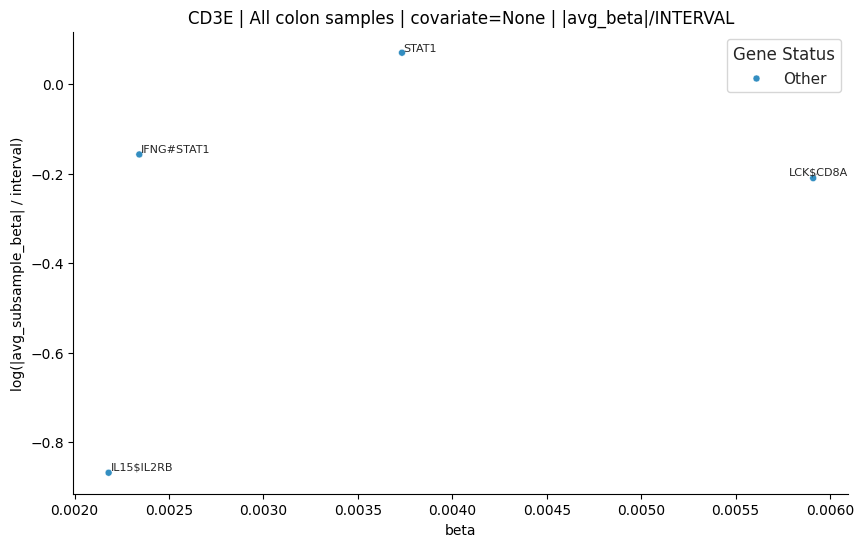

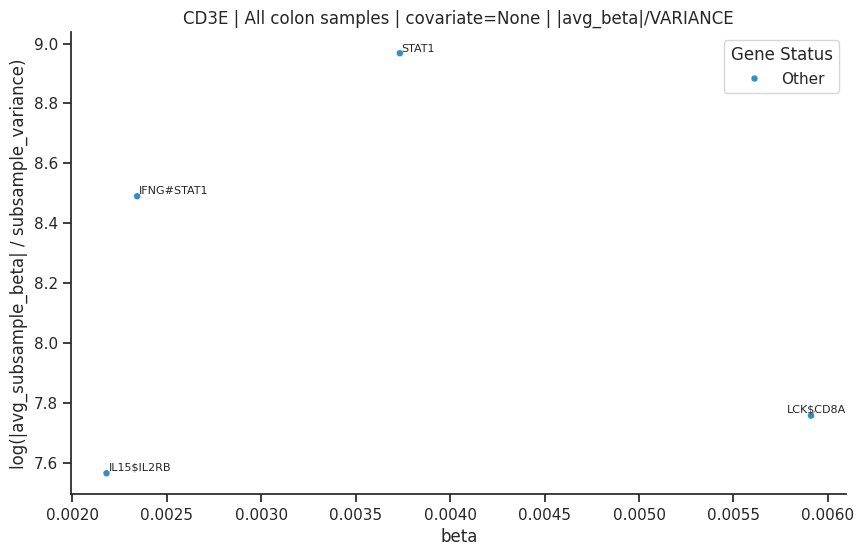

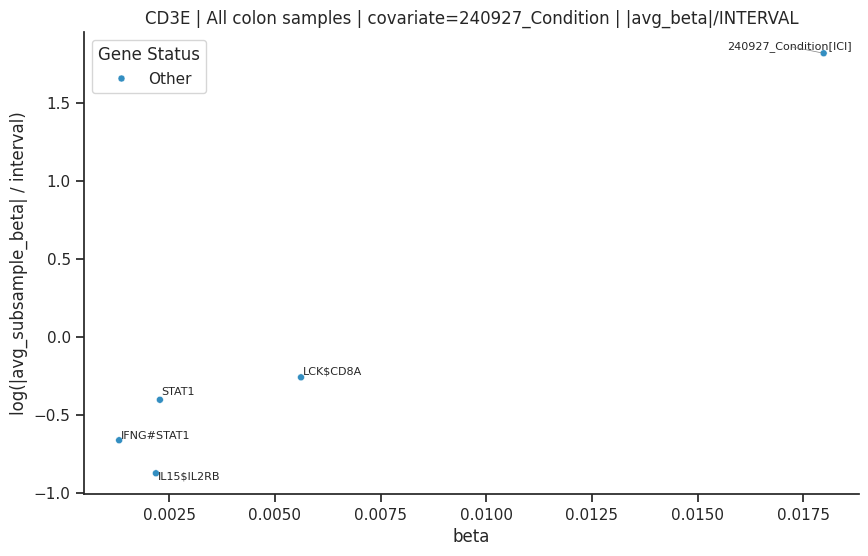

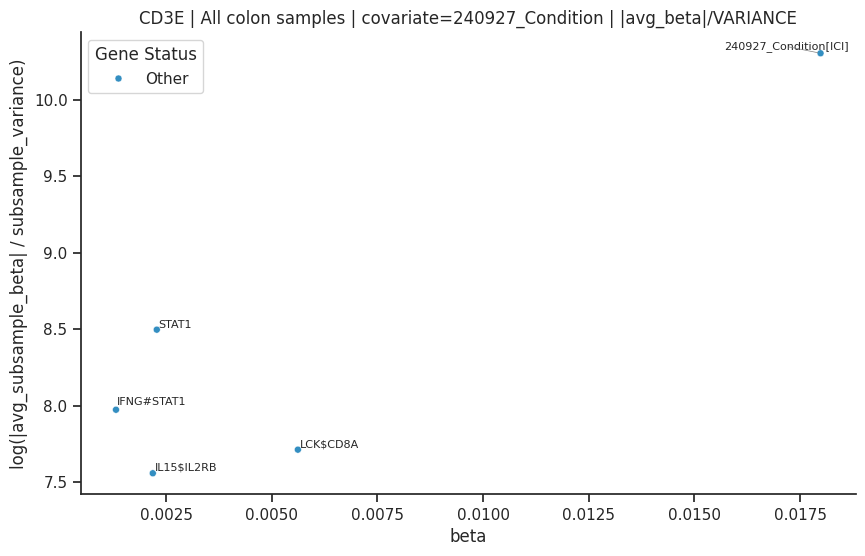

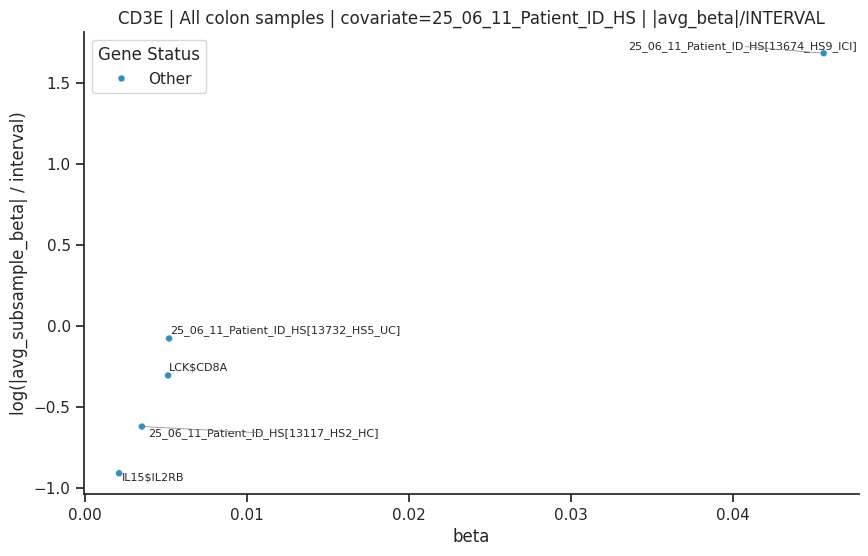

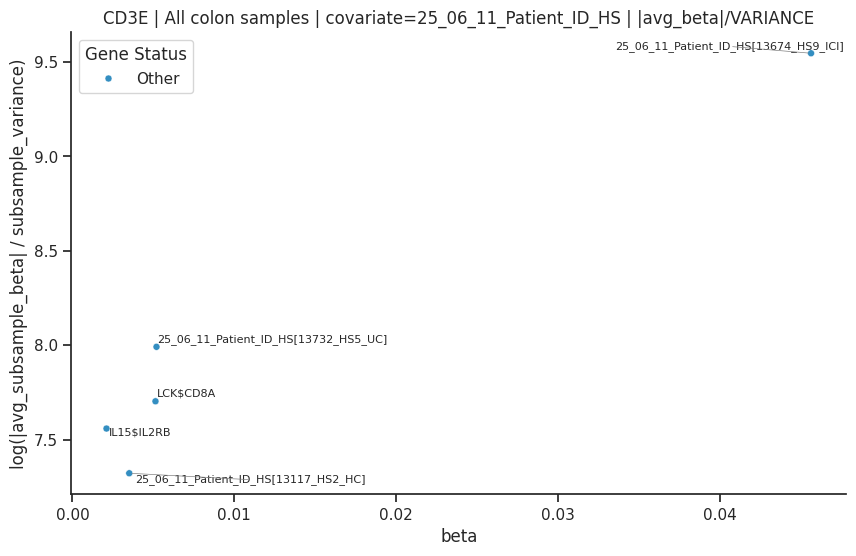

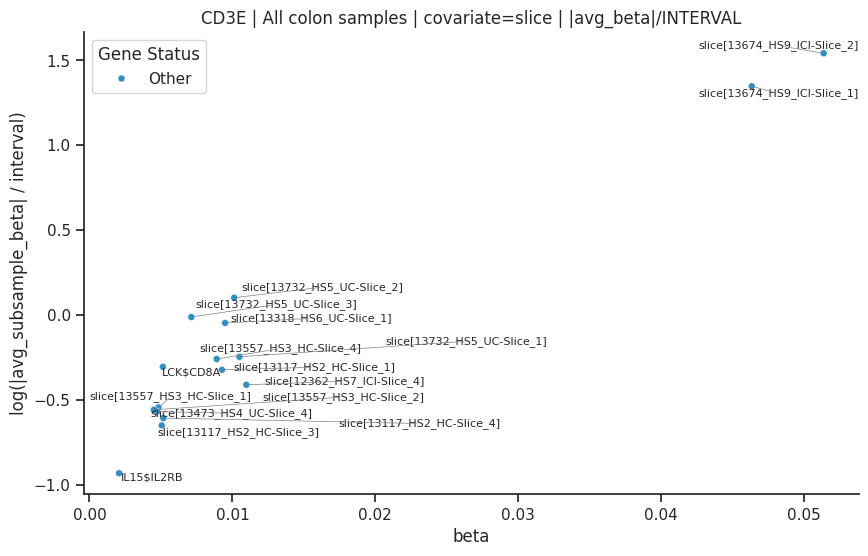

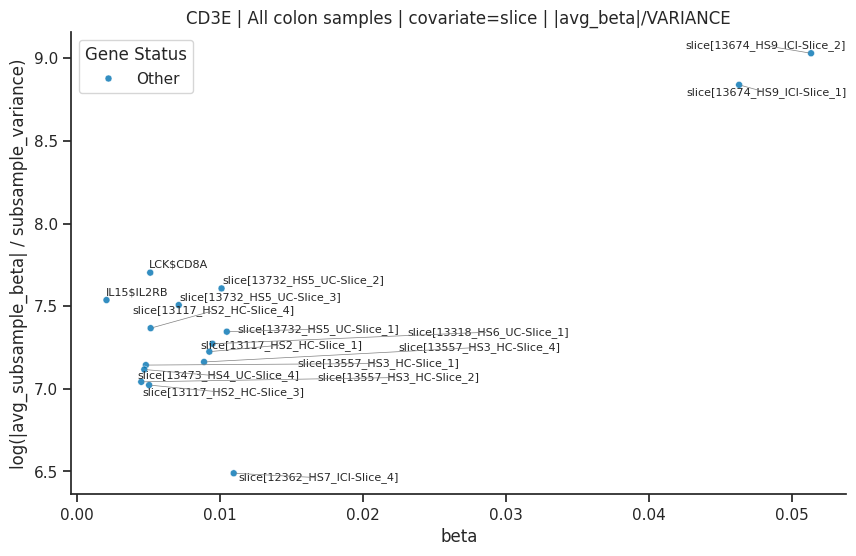

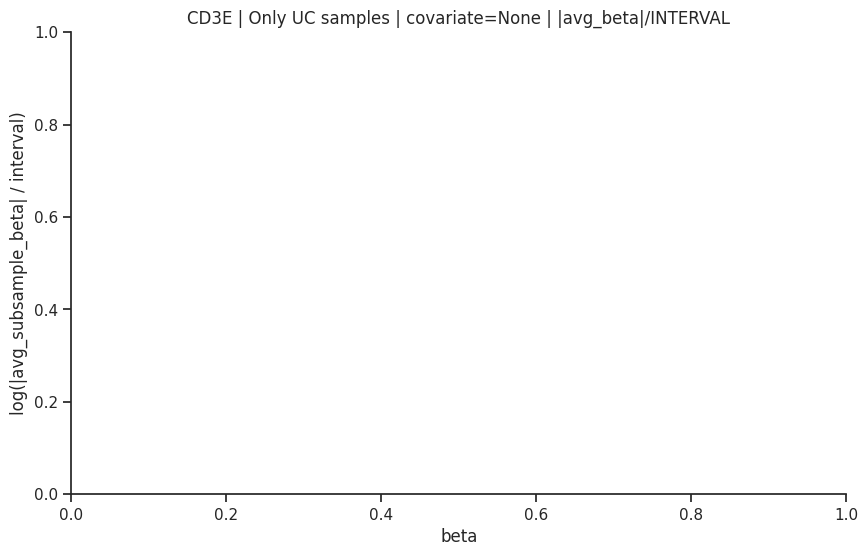

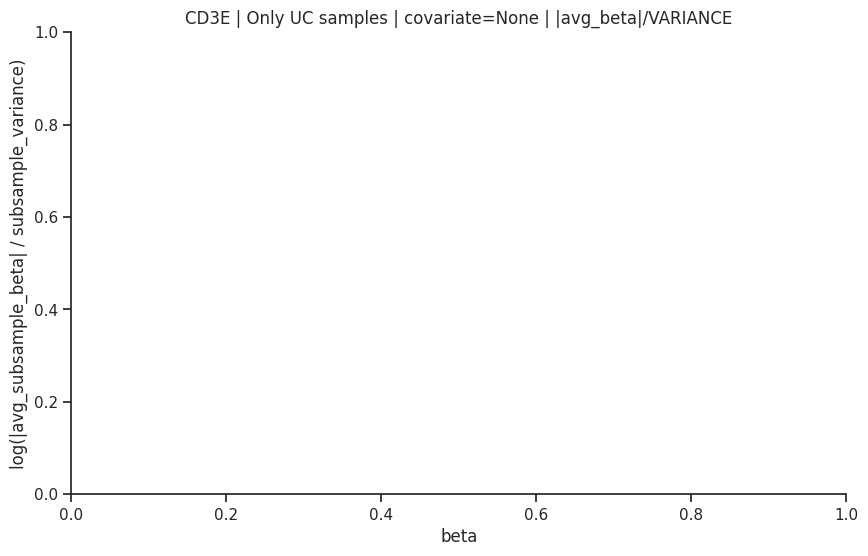

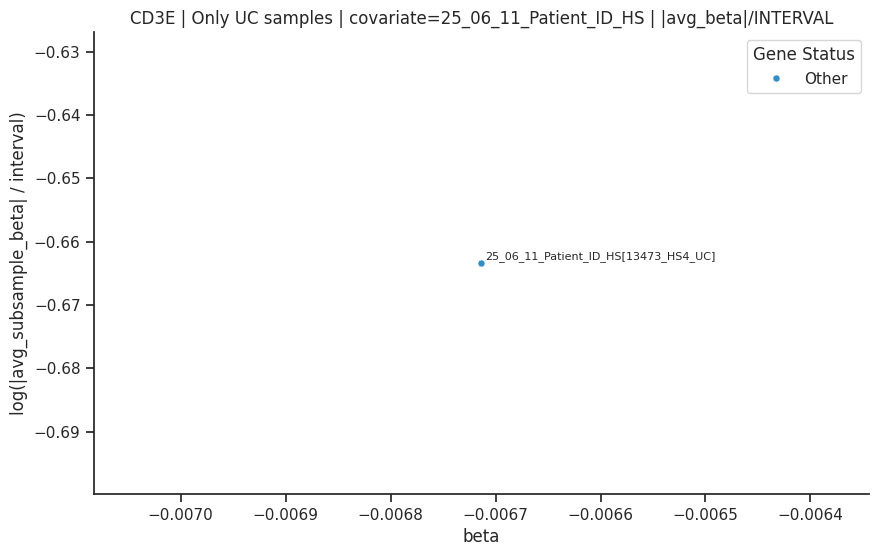

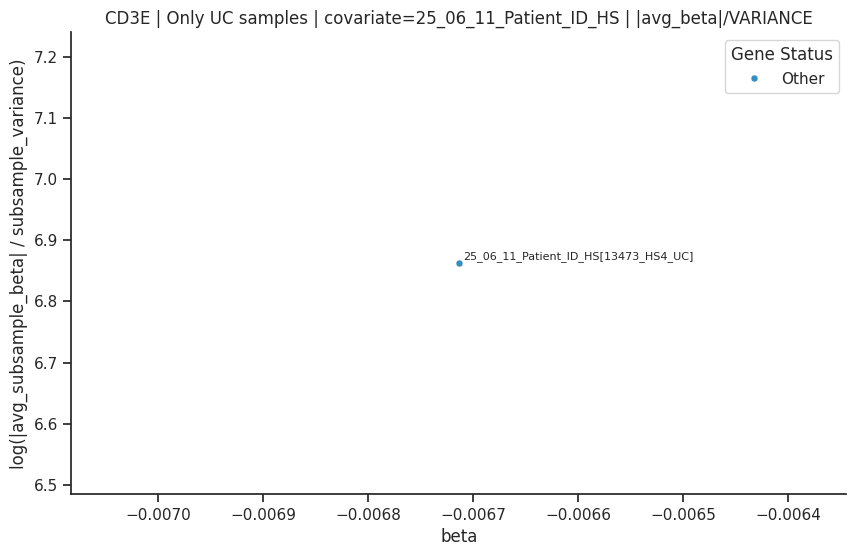

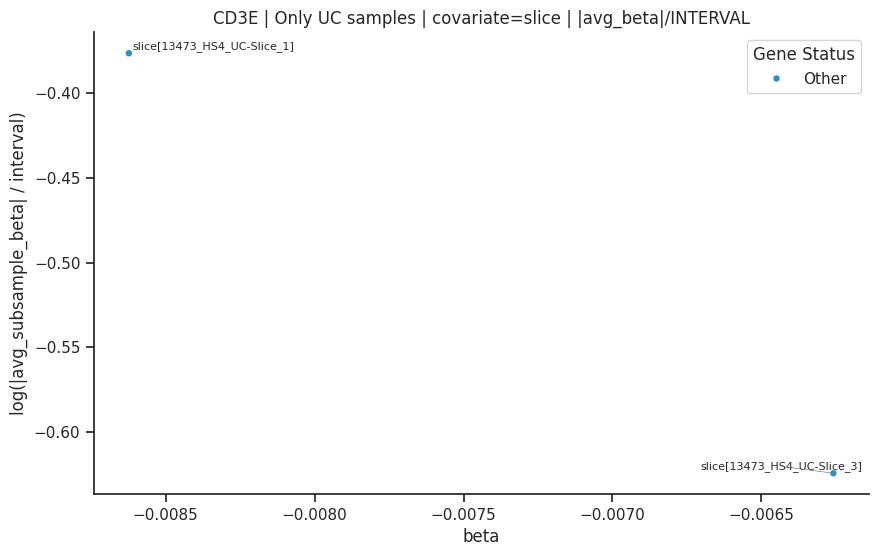

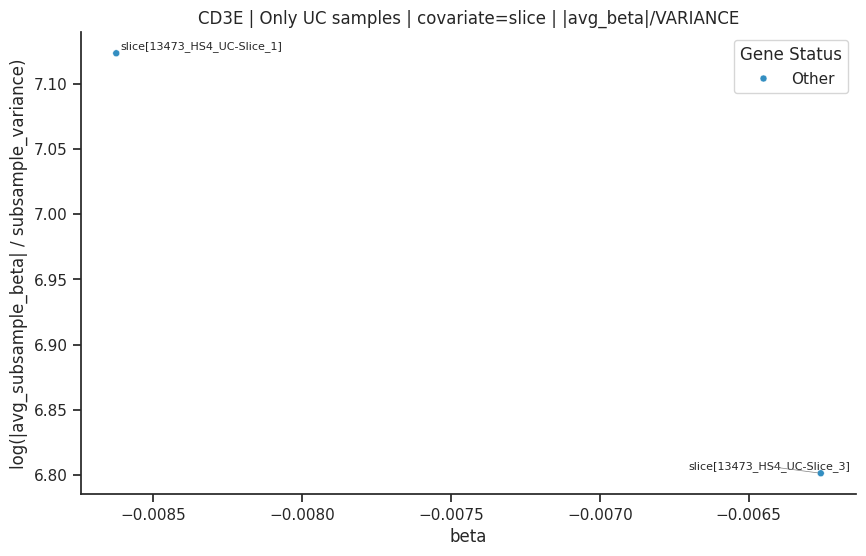

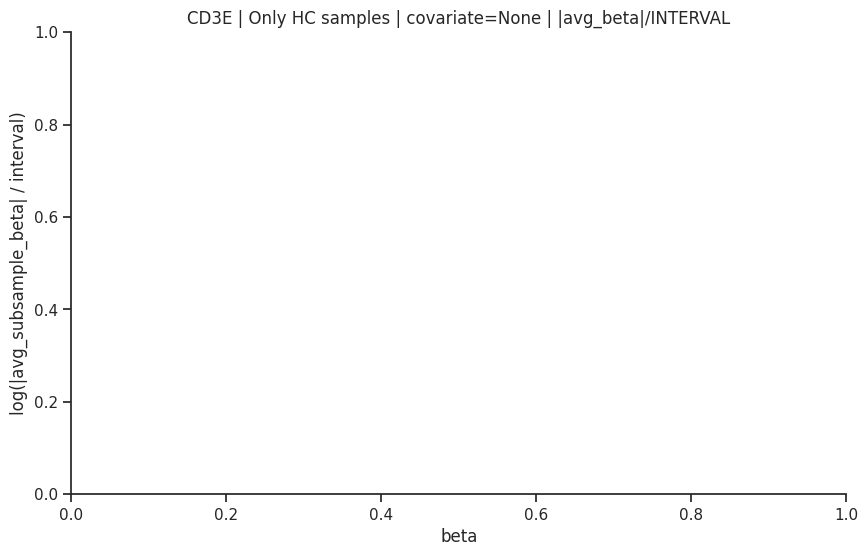

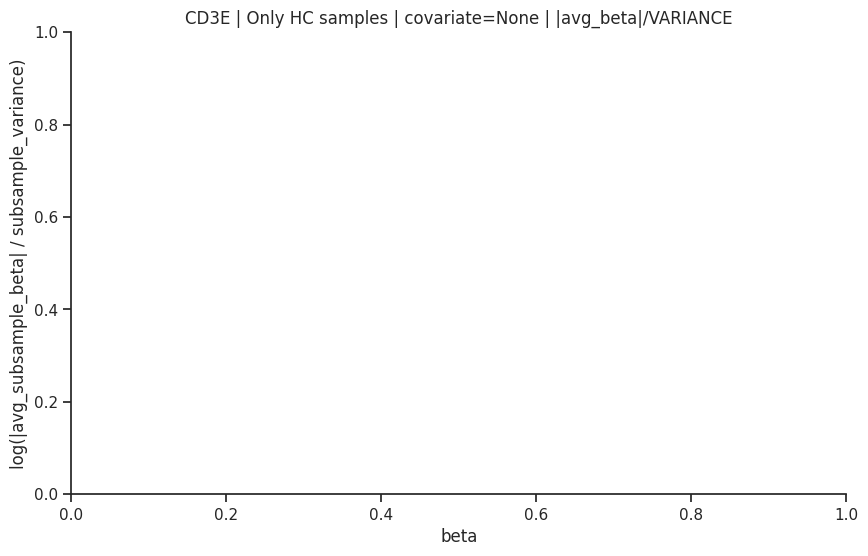

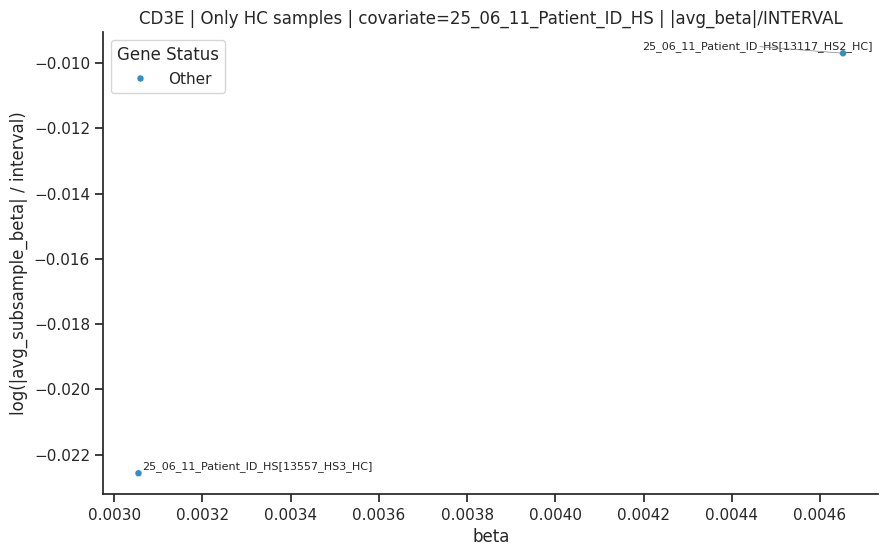

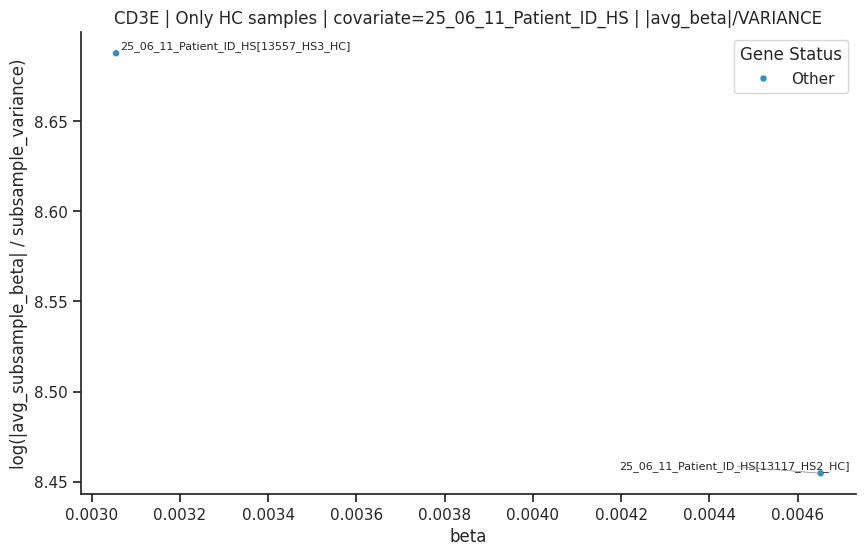

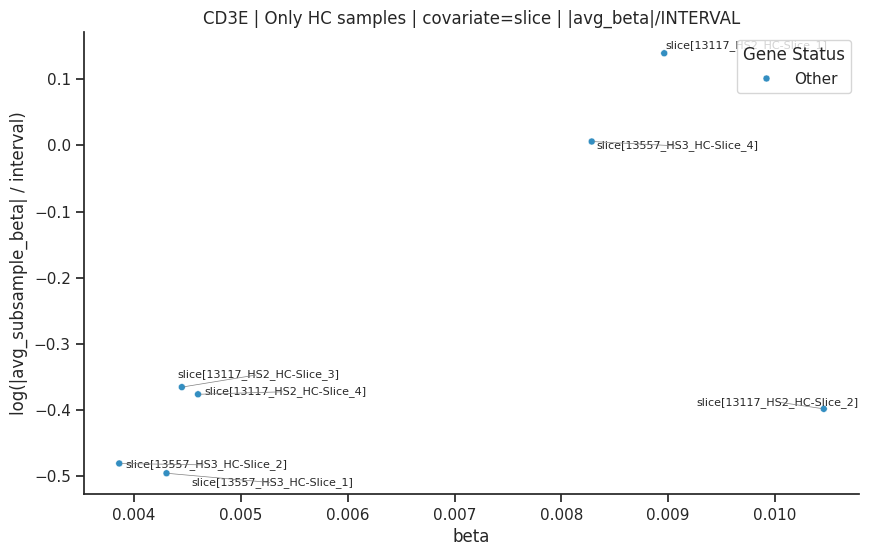

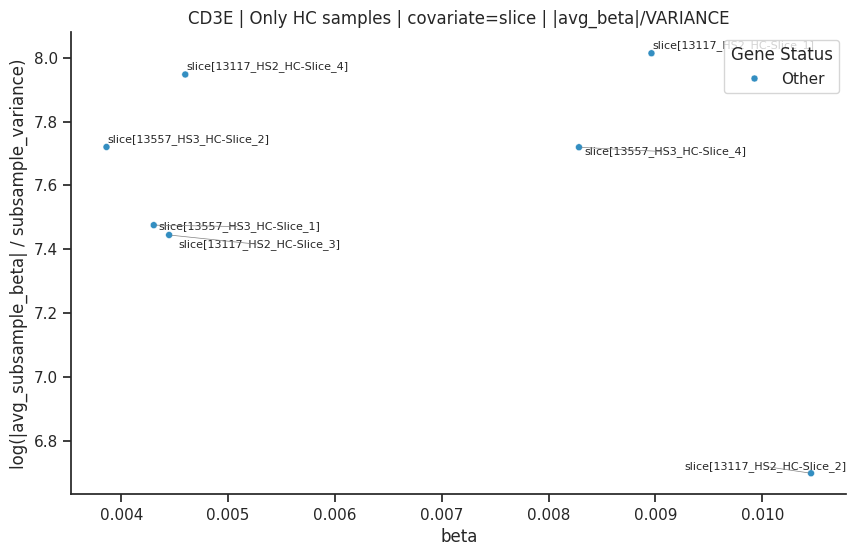

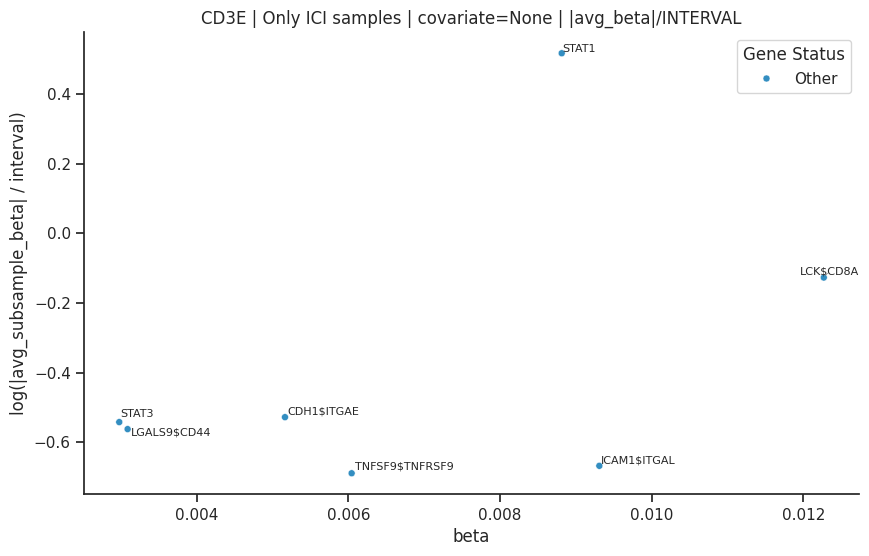

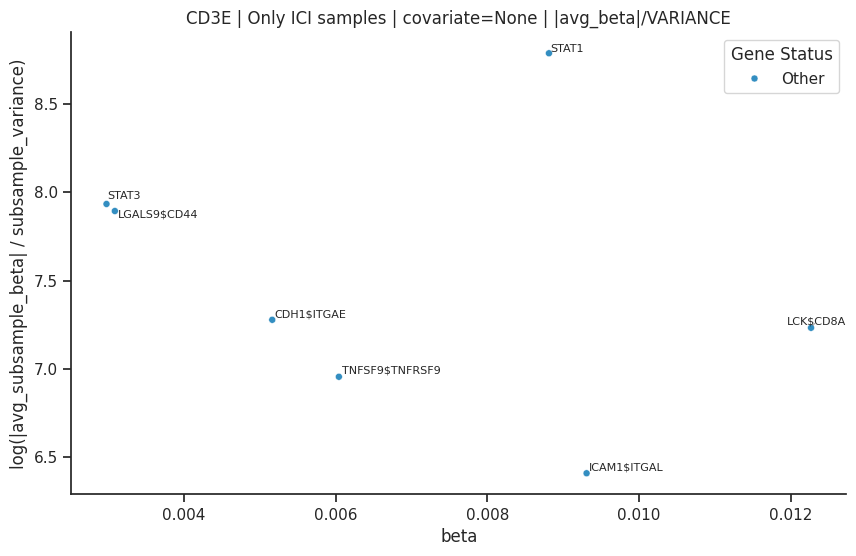

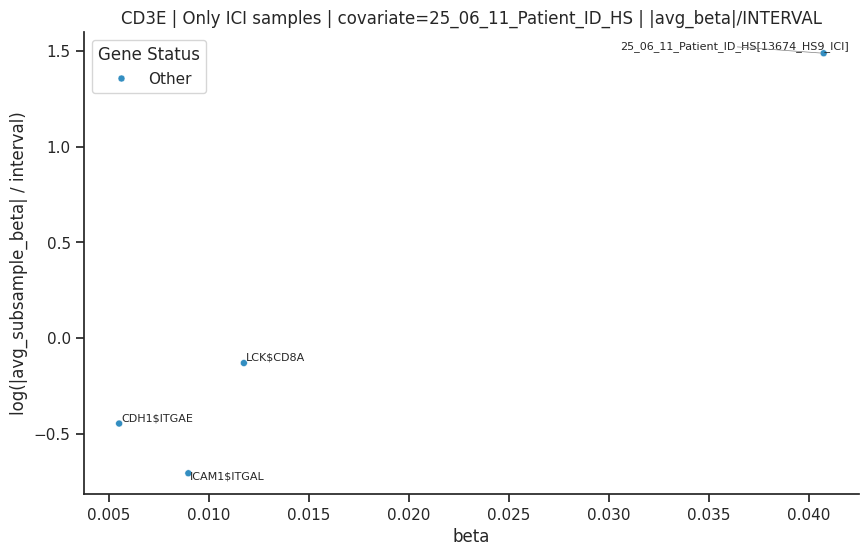

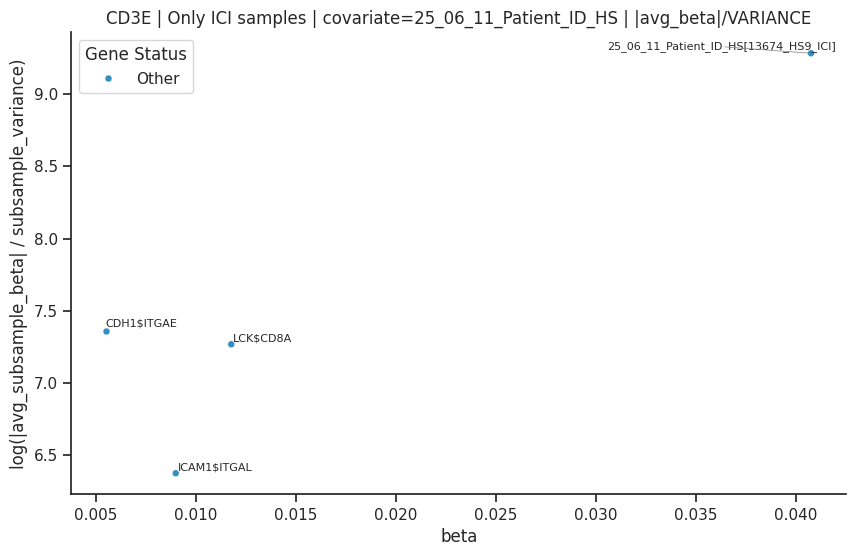

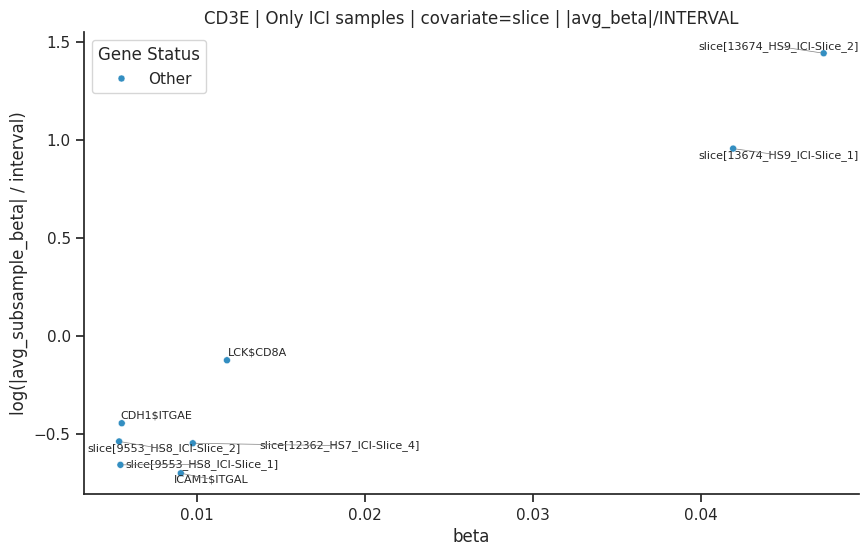

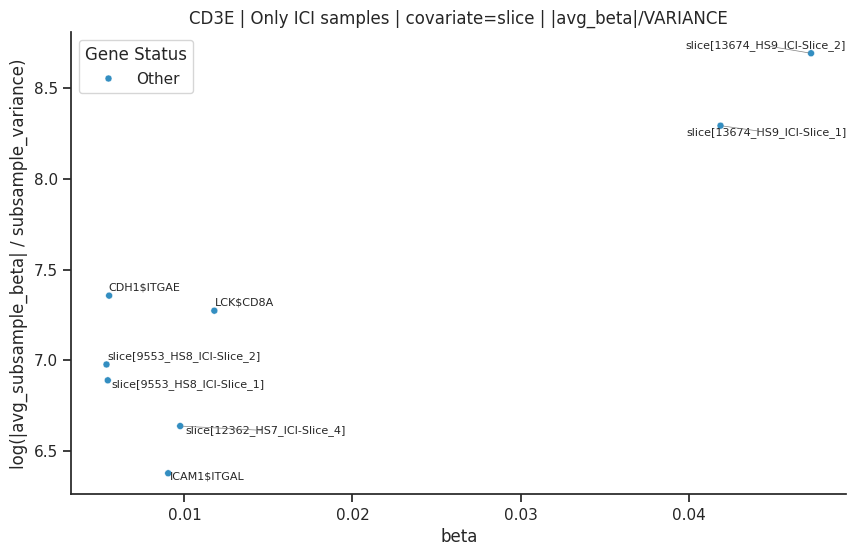

In [6]:
run_colon_gene(SINGLE_GENE)

## Per-signature predictions (subset x batch-covariate grid)

[add_gene_signature 'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION'] factor_mode='union' keep_when_overlap='factor'
  dropped 8 gene(s) from the target: ['CDX2', 'GATA4', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'SOX9']
  kept all 2128 factor(s)

===== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION | All colon samples | IEC | covariate=None =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
32,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,HNF4A,tf,0.032048,0.218031,0.047537,0.265003,110157,0.027666,0.037596,0.031667,0.000005,0.000005,0.029627,0.034074,0.208370,0.226374,0.217612
1903,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,ETV1,tf,0.030991,0.078588,0.006176,0.265003,110157,0.023606,0.039091,0.030860,0.000012,0.000012,0.026626,0.034621,0.068213,0.091548,0.077818
39,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,KLF4,tf,0.029664,0.200004,0.040002,0.265003,110157,0.022408,0.034849,0.029599,0.000006,0.000006,0.027342,0.032483,0.189205,0.207154,0.200727
1365,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,VDR,tf,0.027528,0.187058,0.034991,0.265003,110157,0.023214,0.032893,0.028508,0.000006,0.000007,0.025918,0.030858,0.178851,0.196144,0.187719
33,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,IRF1,tf,0.027212,0.173560,0.030123,0.265003,110157,0.019485,0.030701,0.025939,0.000006,0.000008,0.023363,0.028156,0.164968,0.184577,0.174227
591,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CDH1$CDH1,lr,0.025317,0.183761,0.033768,0.265003,110157,0.010114,0.036856,0.026118,0.000030,0.000030,0.020542,0.031750,0.168565,0.202221,0.186073
1752,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,EPAS1,tf,0.024149,0.166431,0.027699,0.265003,110157,0.019670,0.030749,0.024622,0.000006,0.000006,0.022454,0.026535,0.156548,0.175065,0.166590
527,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,COL2A1$CD44,lr,0.023542,0.070184,0.004926,0.265003,110157,0.015119,0.031372,0.023127,0.000016,0.000016,0.019108,0.027171,0.051502,0.088642,0.069421
1620,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,PPARD,tf,0.023334,0.139300,0.019404,0.265003,110157,0.017496,0.029827,0.024022,0.000006,0.000006,0.021453,0.026343,0.130748,0.147380,0.139774
1360,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,SIRT6,tf,0.022263,0.143703,0.020651,0.265003,110157,0.018194,0.027866,0.022217,0.000006,0.000006,0.019620,0.024836,0.133796,0.153728,0.144501


[add_gene_signature 'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION'] factor_mode='union' keep_when_overlap='factor'
  dropped 8 gene(s) from the target: ['CDX2', 'GATA4', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'SOX9']
  kept all 2128 factor(s)

===== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION | All colon samples | IEC | covariate=240927_Condition =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
32,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,HNF4A,tf,0.032394,0.218031,0.047537,0.265162,110157,0.027956,0.037977,0.032034,0.000005,0.000005,0.030044,0.034473,0.208370,0.226374,0.217612
1903,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,ETV1,tf,0.030954,0.078588,0.006176,0.265162,110157,0.023585,0.039013,0.030801,0.000012,0.000012,0.026581,0.034595,0.068213,0.091548,0.077818
39,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,KLF4,tf,0.029687,0.200004,0.040002,0.265162,110157,0.022445,0.034919,0.029651,0.000006,0.000006,0.027390,0.032501,0.189205,0.207154,0.200727
1365,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,VDR,tf,0.028102,0.187058,0.034991,0.265162,110157,0.023700,0.033416,0.029064,0.000006,0.000007,0.026454,0.031645,0.178851,0.196144,0.187719
33,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,IRF1,tf,0.026024,0.173560,0.030123,0.265162,110157,0.017995,0.029482,0.024748,0.000006,0.000008,0.021936,0.027073,0.164968,0.184577,0.174227
591,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CDH1$CDH1,lr,0.025334,0.183761,0.033768,0.265162,110157,0.010146,0.036873,0.026164,0.000030,0.000031,0.020602,0.031768,0.168565,0.202221,0.186073
1752,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,EPAS1,tf,0.024486,0.166431,0.027699,0.265162,110157,0.020193,0.030975,0.024953,0.000006,0.000006,0.022806,0.026848,0.156548,0.175065,0.166590
527,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,COL2A1$CD44,lr,0.023533,0.070184,0.004926,0.265162,110157,0.015099,0.031292,0.023107,0.000016,0.000016,0.019090,0.027145,0.051502,0.088642,0.069421
1620,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,PPARD,tf,0.023471,0.139300,0.019404,0.265162,110157,0.017595,0.030026,0.024156,0.000006,0.000006,0.021657,0.026466,0.130748,0.147380,0.139774
1360,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,SIRT6,tf,0.022216,0.143703,0.020651,0.265162,110157,0.018130,0.027768,0.022167,0.000006,0.000006,0.019485,0.024777,0.133796,0.153728,0.144501


[add_gene_signature 'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION'] factor_mode='union' keep_when_overlap='factor'
  dropped 8 gene(s) from the target: ['CDX2', 'GATA4', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'SOX9']
  kept all 2128 factor(s)

===== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION | All colon samples | IEC | covariate=25_06_11_Patient_ID_HS =====


...

/global/home/users/fosterangus/Projects/MetabTravLR/SpaceTravLR/metab_processing/LinearRegression/signature_helpers.py:180: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  _, ax = plt.subplots(figsize=figsize)


[add_gene_signature 'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION'] factor_mode='union' keep_when_overlap='factor'
  dropped 8 gene(s) from the target: ['CDX2', 'GATA4', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'SOX9']
  kept all 2128 factor(s)

===== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION | Only ICI samples | IEC | covariate=25_06_11_Patient_ID_HS =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
527,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,COL2A1$CD44,lr,0.039946,0.079407,0.006305,0.321353,32759,0.026549,0.051058,0.039737,0.000030,0.000030,0.035134,0.044390,0.062060,0.114916,0.081670
33,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,IRF1,tf,0.034838,0.247340,0.061177,0.321353,32759,0.013707,0.042215,0.031721,0.000028,0.000037,0.026890,0.036787,0.225360,0.264837,0.248143
1620,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,PPARD,tf,0.034146,0.166233,0.027633,0.321353,32759,0.021851,0.042596,0.033268,0.000022,0.000023,0.028730,0.038315,0.149398,0.185238,0.165804
39,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,KLF4,tf,0.033175,0.212731,0.045254,0.321353,32759,0.023135,0.043953,0.033389,0.000019,0.000019,0.028989,0.038170,0.197309,0.229607,0.214003
32,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,HNF4A,tf,0.031457,0.218126,0.047579,0.321353,32759,0.021422,0.041666,0.030273,0.000026,0.000028,0.024110,0.036551,0.202072,0.231415,0.217654
591,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CDH1$CDH1,lr,0.029533,0.147276,0.021690,0.321353,32759,0.007008,0.048946,0.024255,0.000109,0.000137,0.012282,0.035080,0.115981,0.188277,0.144729
79,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,STAT1,tf,0.028596,0.226909,0.051488,0.321353,32759,0.013108,0.038984,0.027868,0.000029,0.000030,0.022584,0.032571,0.211706,0.247918,0.227858
359,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,TNF$TNFRSF1A,lr,0.027731,0.123651,0.015290,0.321353,32759,0.003259,0.038830,0.022777,0.000087,0.000112,0.012161,0.034347,0.086496,0.160380,0.121778
1365,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,VDR,tf,0.027604,0.179998,0.032399,0.321353,32759,0.014312,0.035435,0.025682,0.000022,0.000025,0.020792,0.030249,0.163600,0.197235,0.178232
416,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,GZMA$F2RL1,lr,0.026289,0.176691,0.031220,0.321353,32759,0.013282,0.042749,0.026942,0.000048,0.000048,0.019303,0.034847,0.160181,0.191714,0.177800


[add_gene_signature 'GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION'] factor_mode='union' keep_when_overlap='factor'
  dropped 8 gene(s) from the target: ['CDX2', 'GATA4', 'HIF1A', 'HOXA5', 'IL6ST', 'KLF5', 'PRDM1', 'SOX9']
  kept all 2128 factor(s)

===== GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION | Only ICI samples | IEC | covariate=slice =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
2132,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,slice[13674_HS9_ICI-Slice_1],onehot,0.053354,0.105637,0.011159,0.322542,32759,-0.019369,0.094969,0.050786,0.000450,0.000457,0.035968,0.074321,0.092087,0.116735,0.107281
527,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,COL2A1$CD44,lr,0.039654,0.079407,0.006305,0.322542,32759,0.026243,0.050614,0.039545,0.000029,0.000029,0.034701,0.043929,0.062060,0.114916,0.081670
33,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,IRF1,tf,0.034703,0.247340,0.061177,0.322542,32759,0.013658,0.042002,0.031401,0.000027,0.000038,0.026704,0.036228,0.225360,0.264837,0.248143
1620,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,PPARD,tf,0.034266,0.166233,0.027633,0.322542,32759,0.021990,0.042529,0.033324,0.000022,0.000023,0.028635,0.038257,0.149398,0.185238,0.165804
39,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,KLF4,tf,0.031843,0.212731,0.045254,0.322542,32759,0.021717,0.042867,0.032078,0.000019,0.000019,0.027862,0.036876,0.197309,0.229607,0.214003
32,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,HNF4A,tf,0.030057,0.218126,0.047579,0.322542,32759,0.020404,0.039830,0.028894,0.000027,0.000028,0.022887,0.034999,0.202072,0.231415,0.217654
591,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,CDH1$CDH1,lr,0.030000,0.147276,0.021690,0.322542,32759,0.007572,0.049895,0.024860,0.000109,0.000136,0.013116,0.035940,0.115981,0.188277,0.144729
2133,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,slice[13674_HS9_ICI-Slice_2],onehot,-0.028658,-0.002177,0.000005,0.322542,32759,-0.075260,0.012304,-0.035578,0.000505,0.000553,-0.058079,-0.008761,-0.011612,0.006805,-0.002726
79,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,STAT1,tf,0.028277,0.226909,0.051488,0.322542,32759,0.013243,0.038383,0.027667,0.000029,0.000029,0.022497,0.032643,0.211706,0.247918,0.227858
359,GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION,TNF$TNFRSF1A,lr,0.027315,0.123651,0.015290,0.322542,32759,0.002894,0.038078,0.022282,0.000087,0.000113,0.011707,0.033888,0.086496,0.160380,0.121778


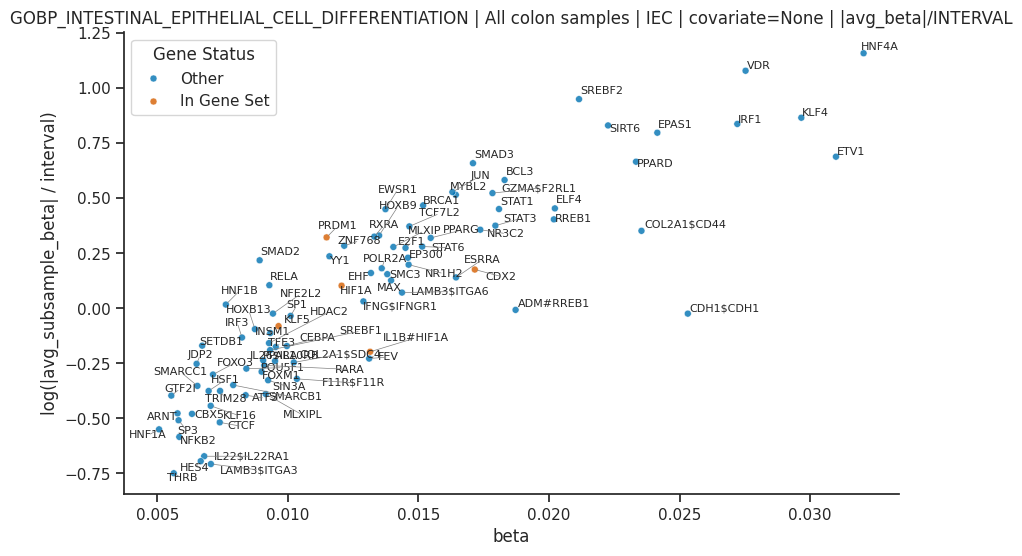

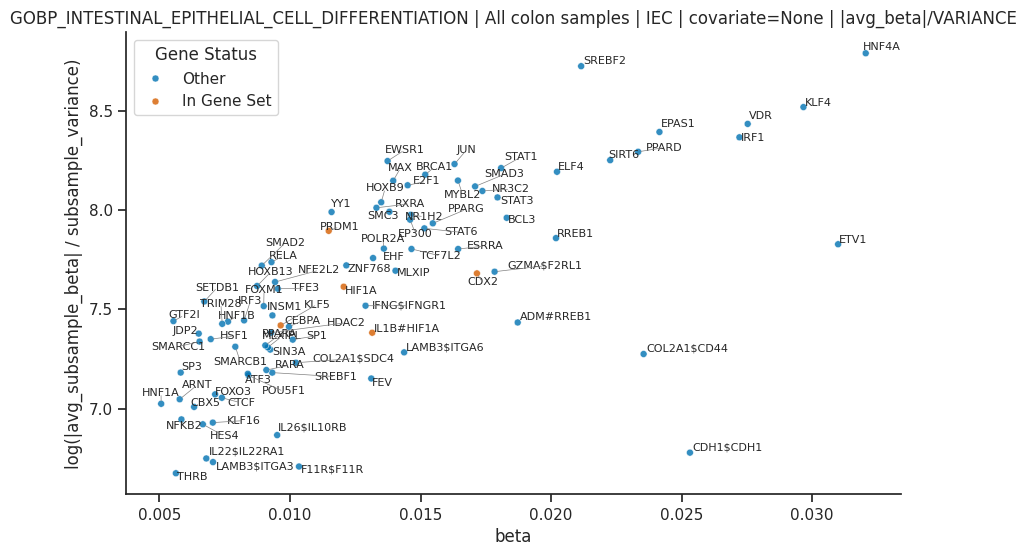

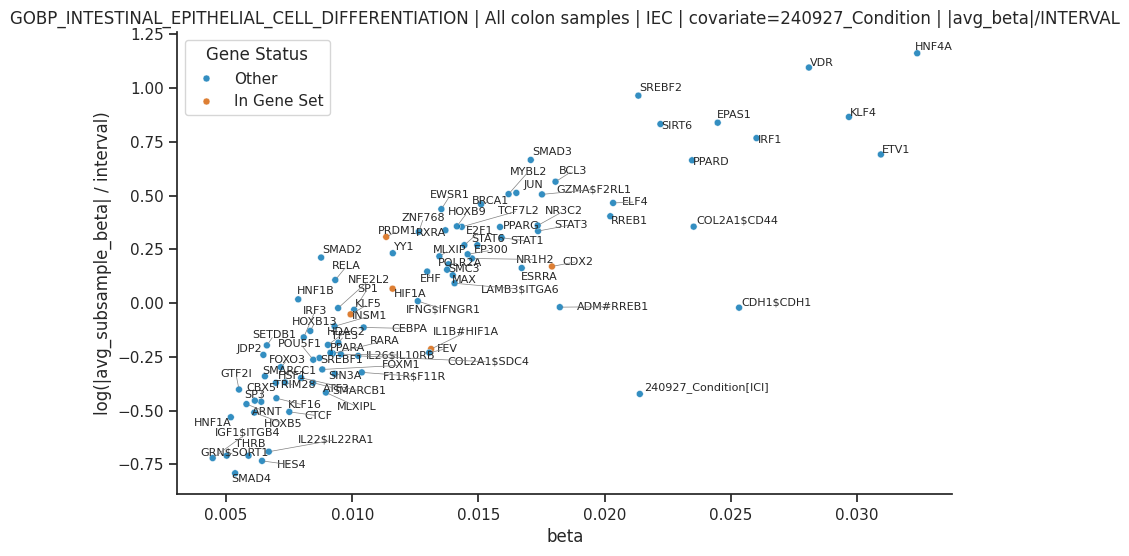

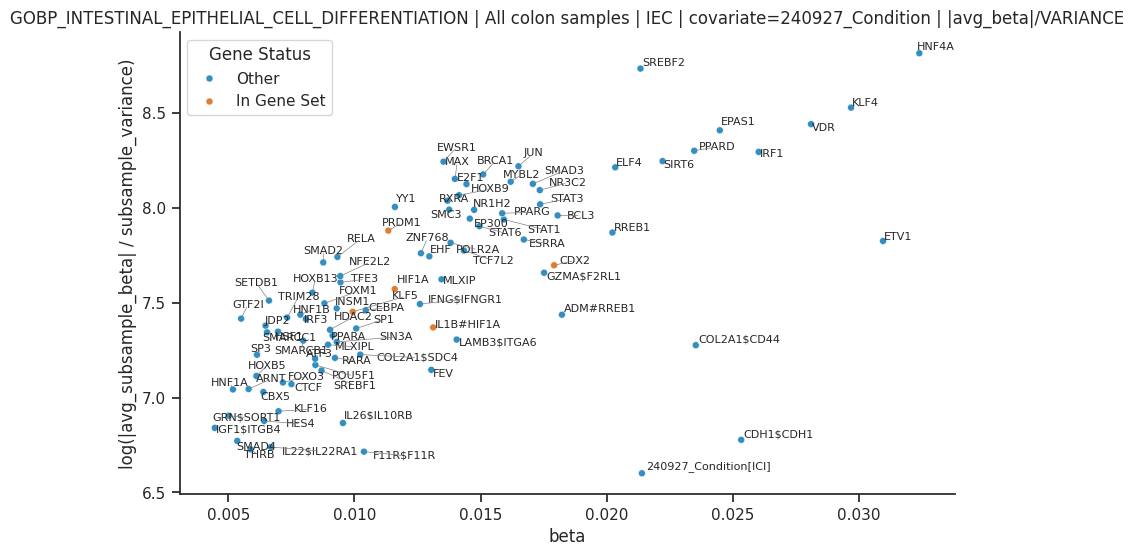

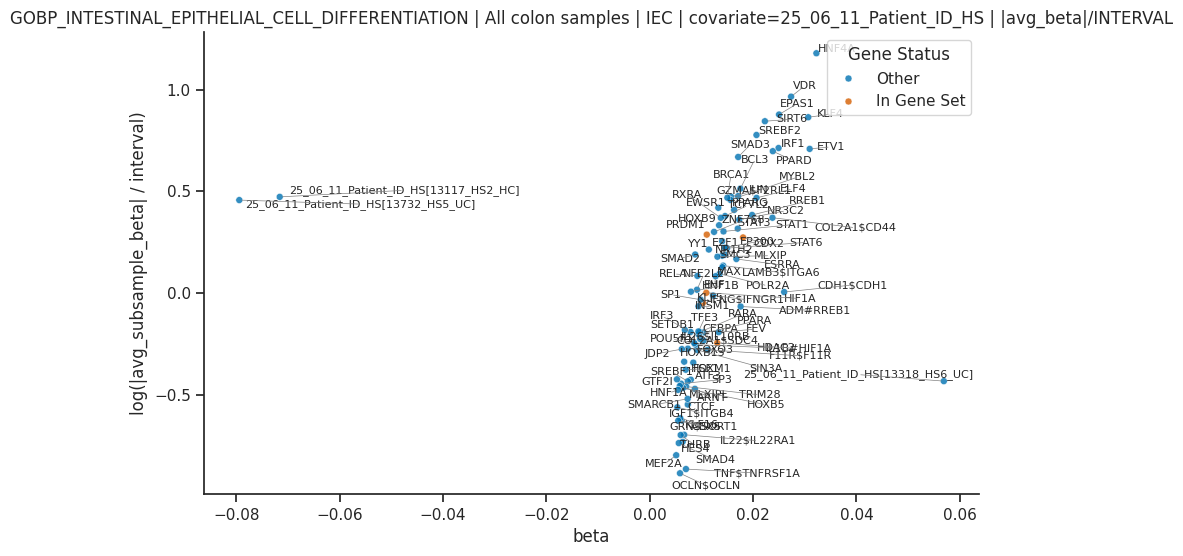

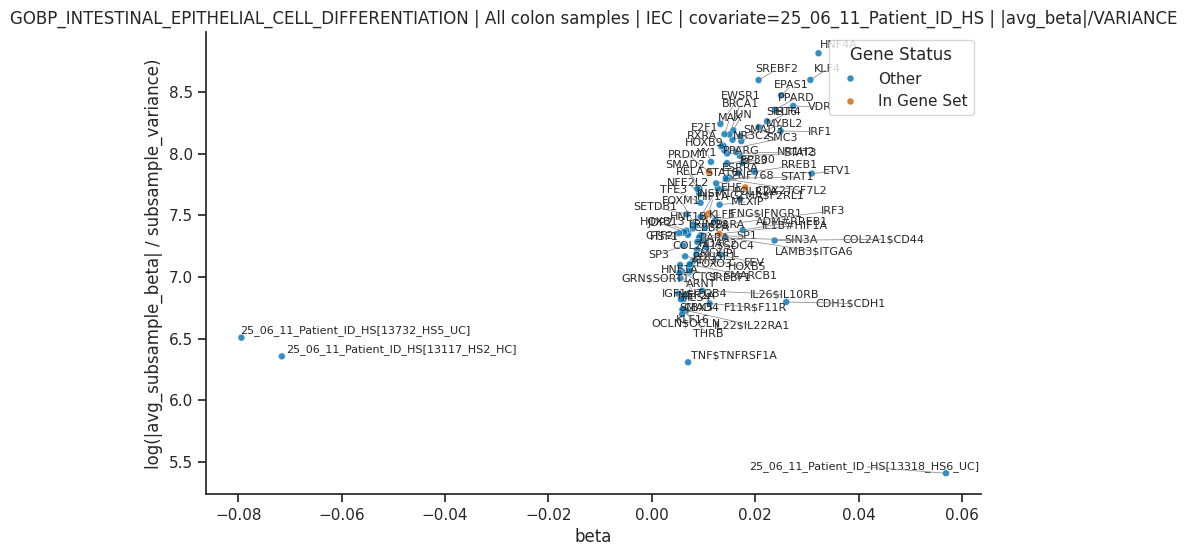

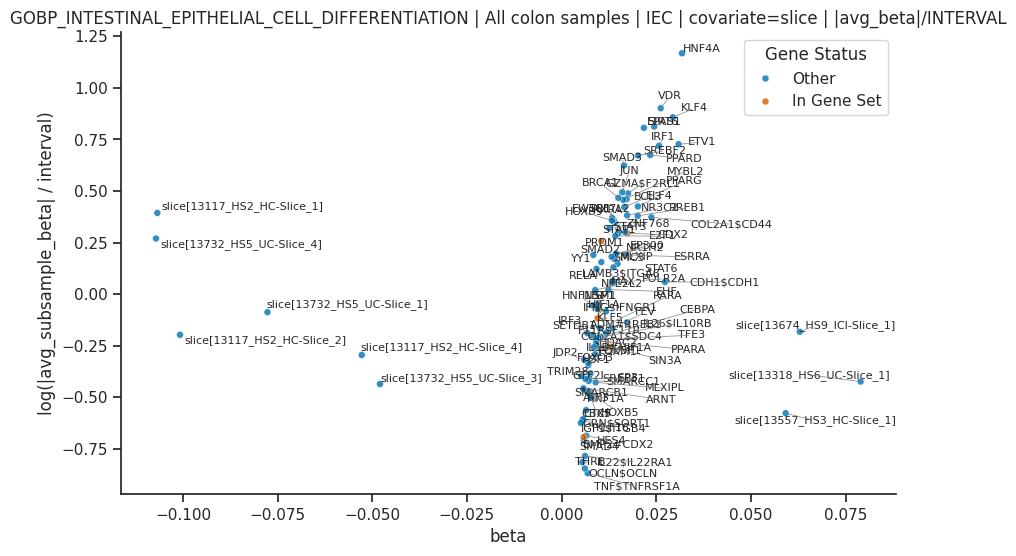

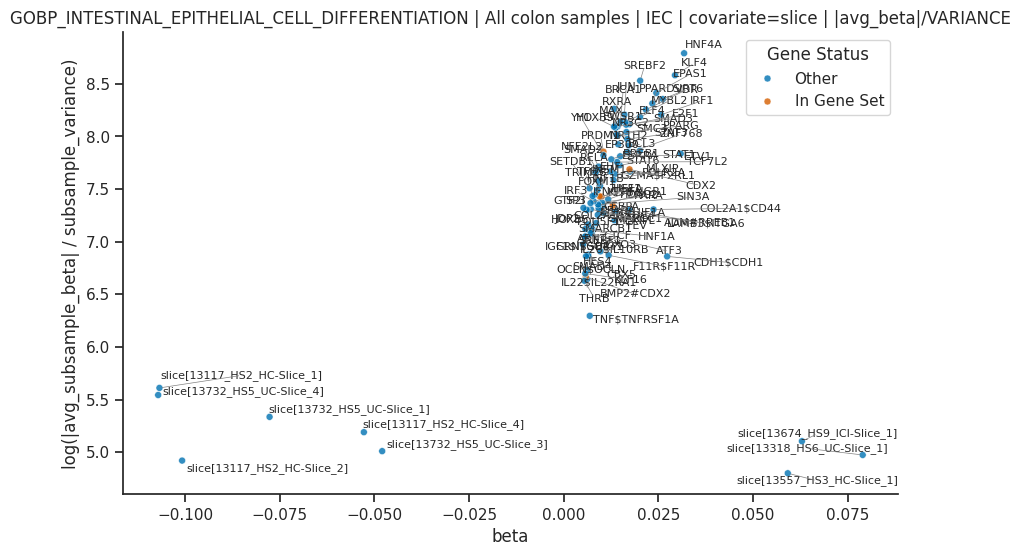

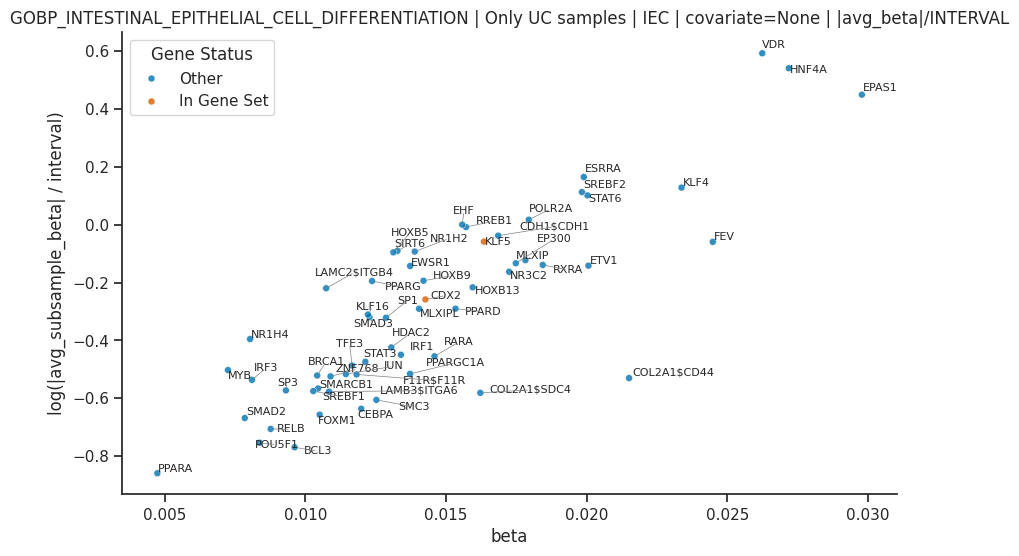

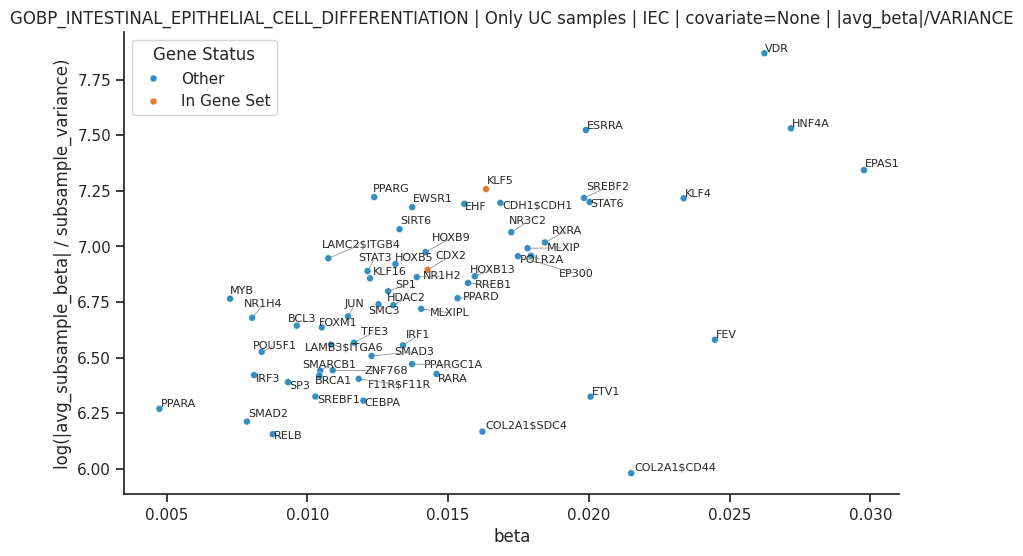

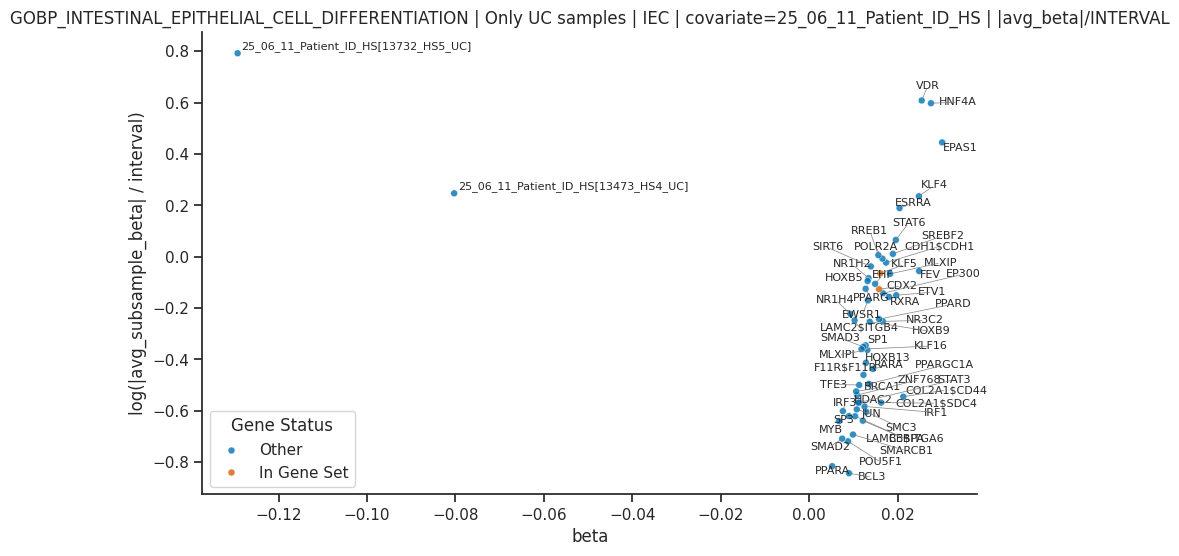

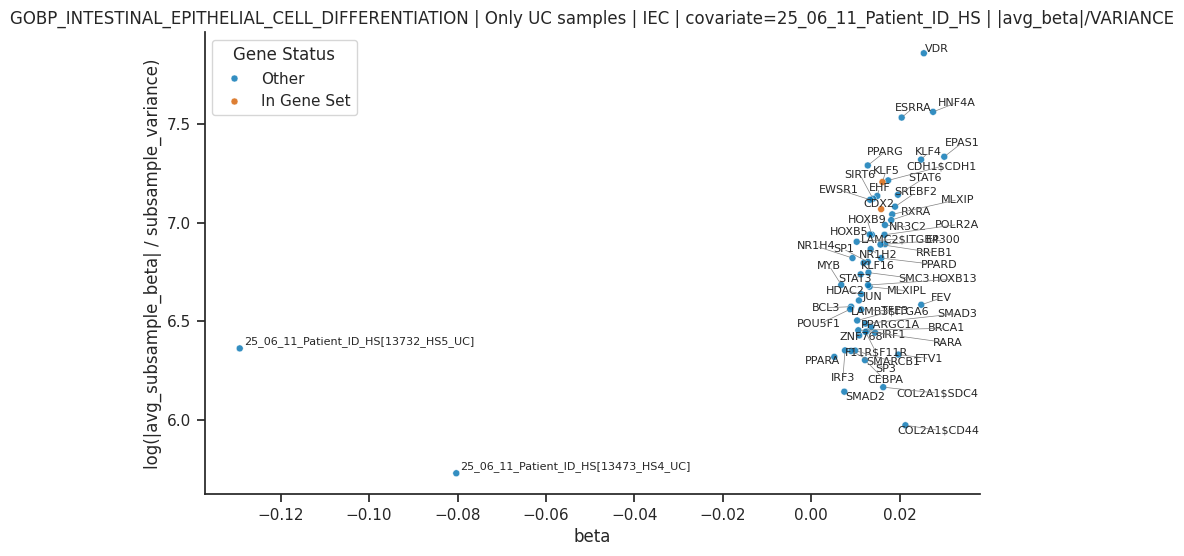

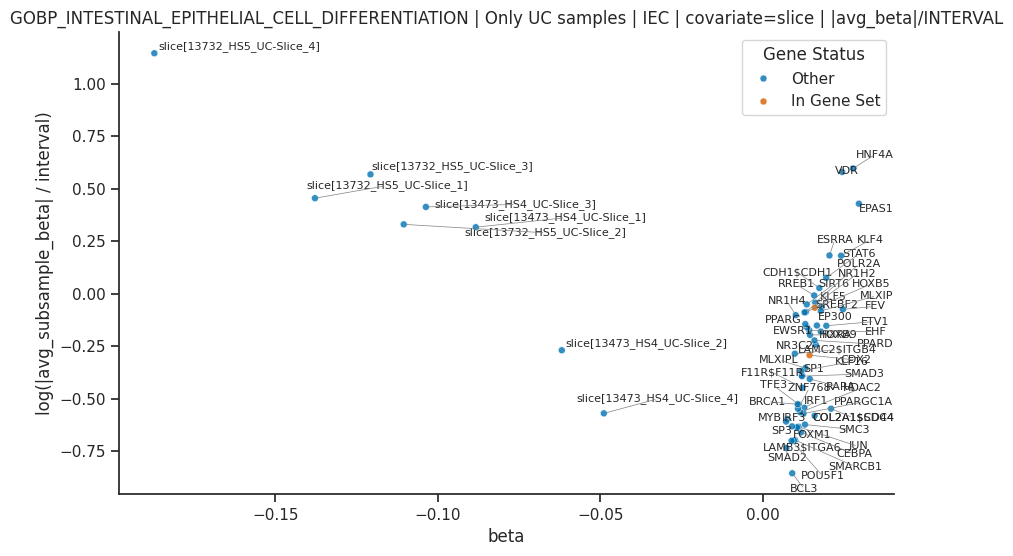

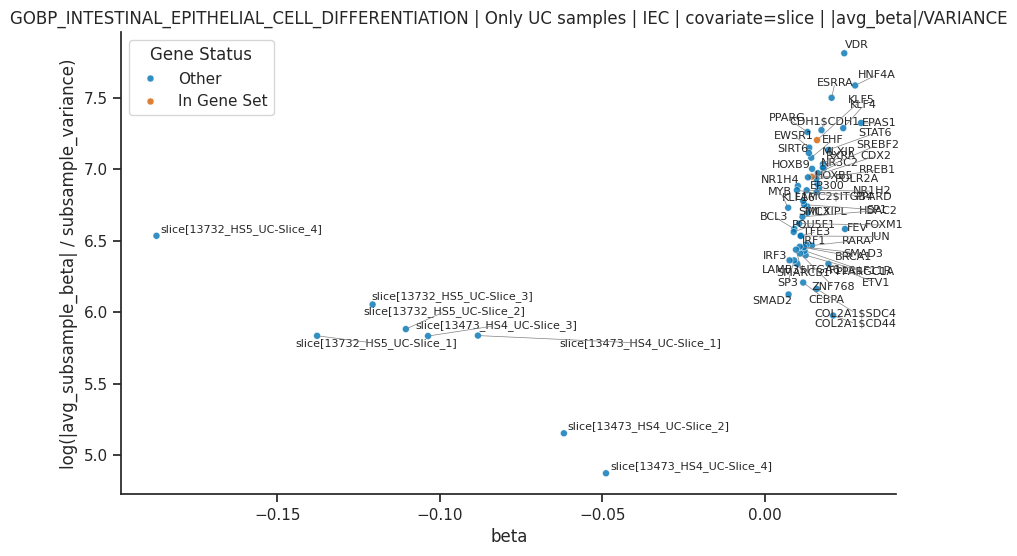

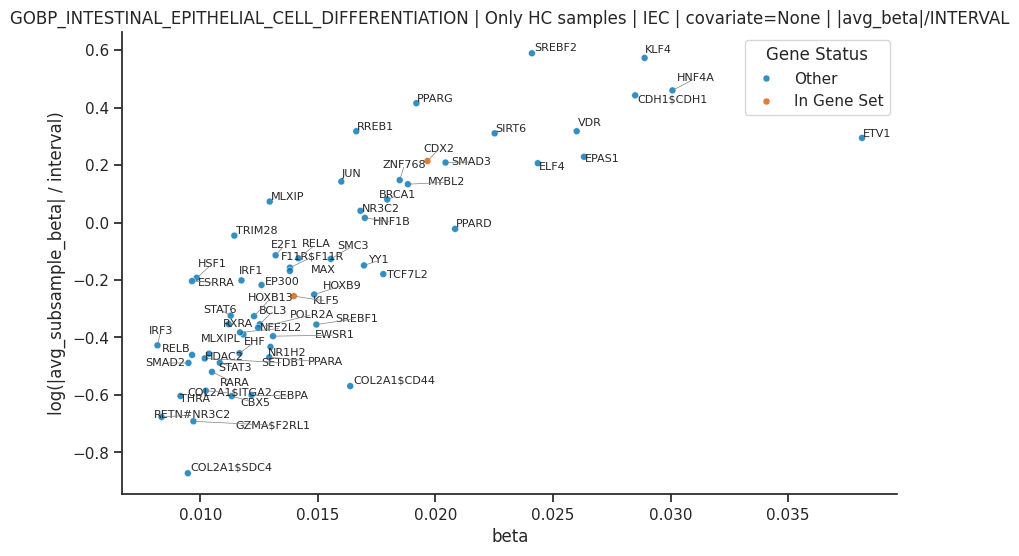

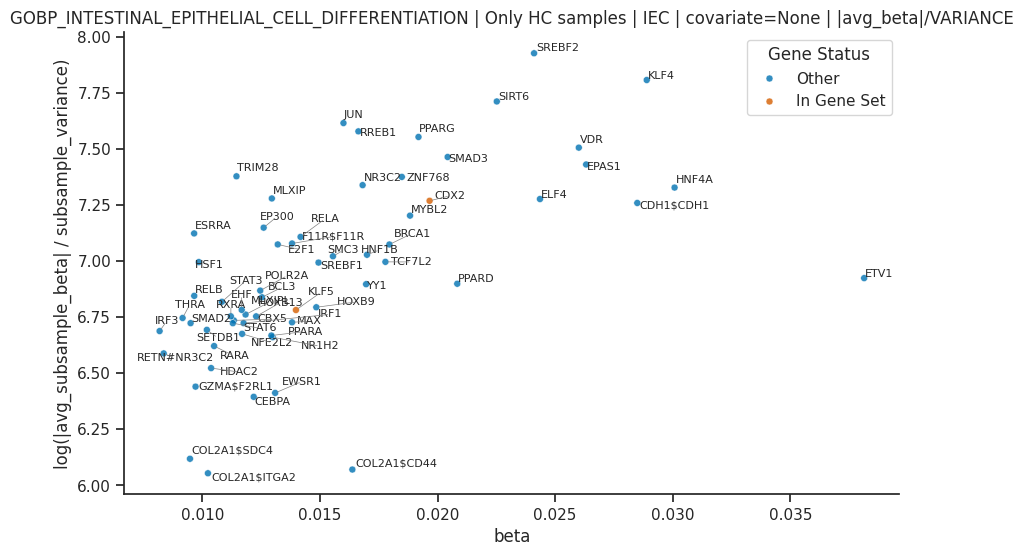

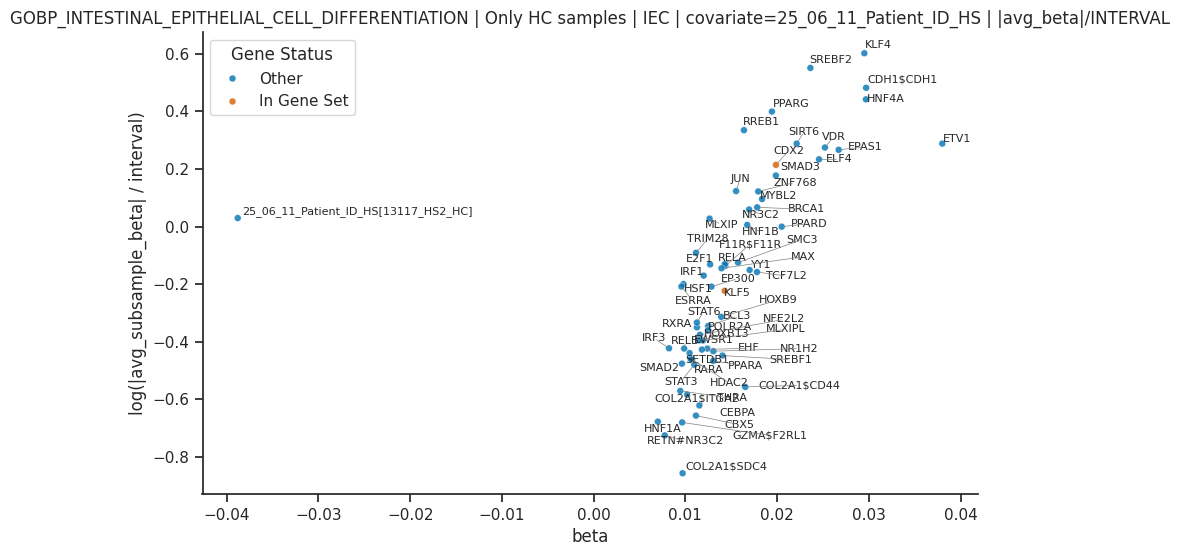

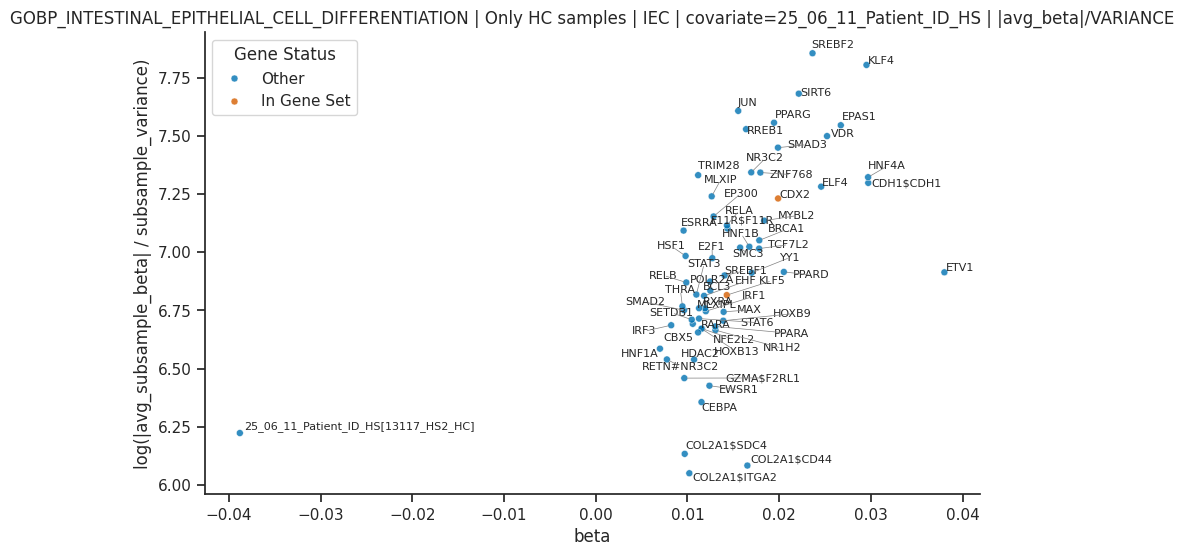

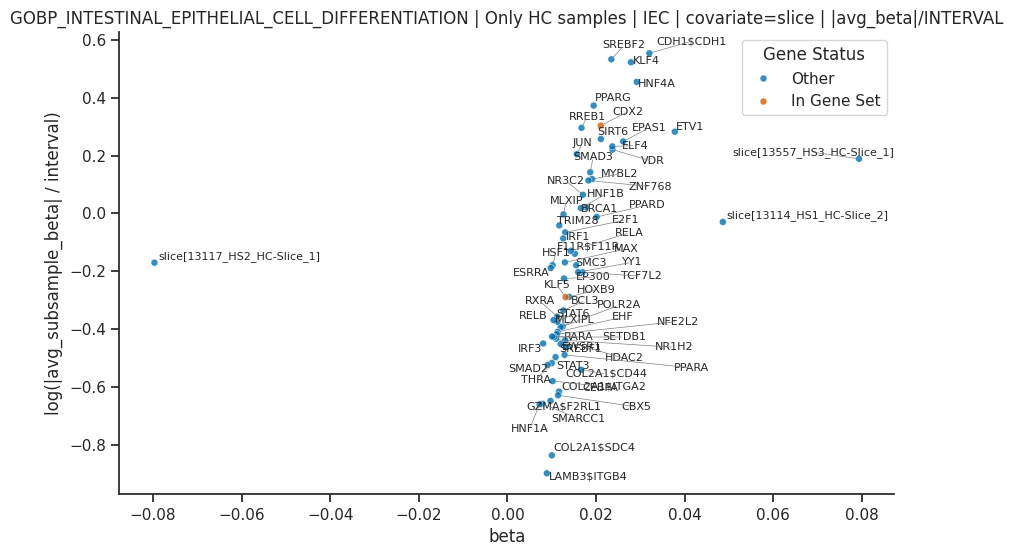

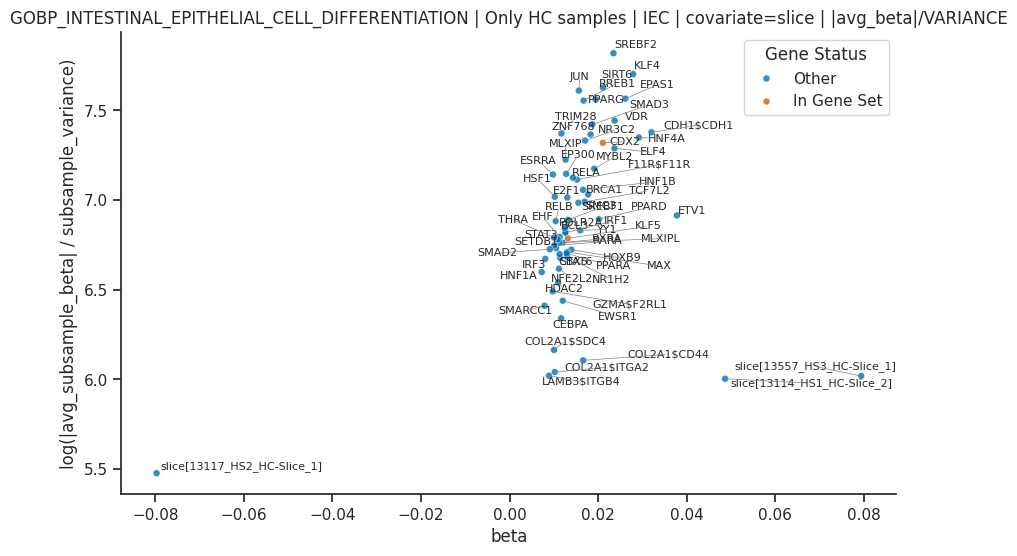

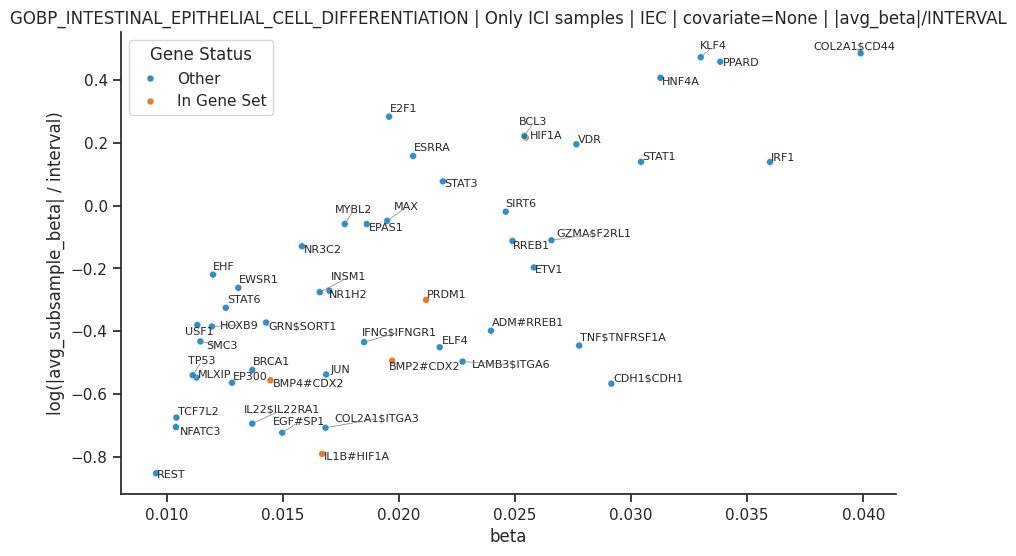

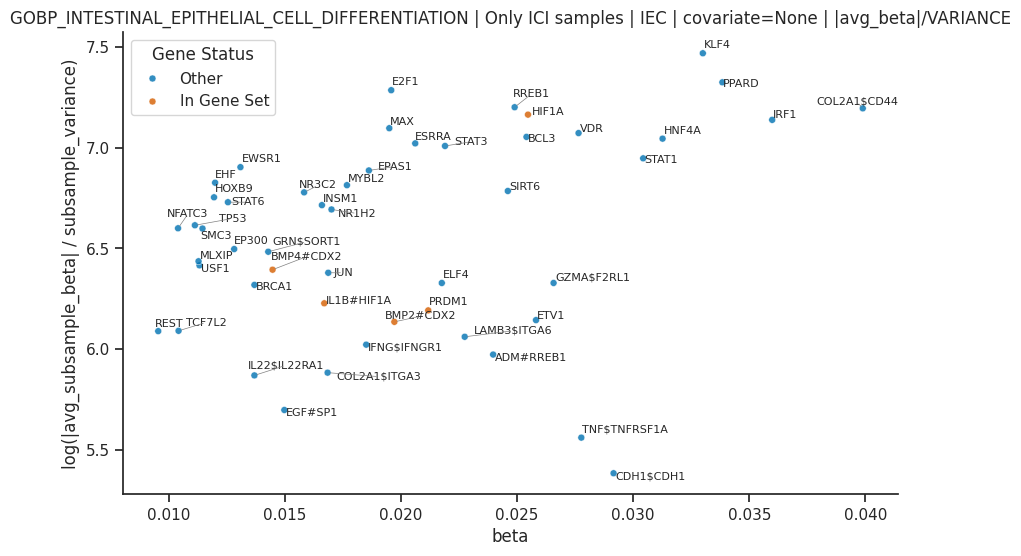

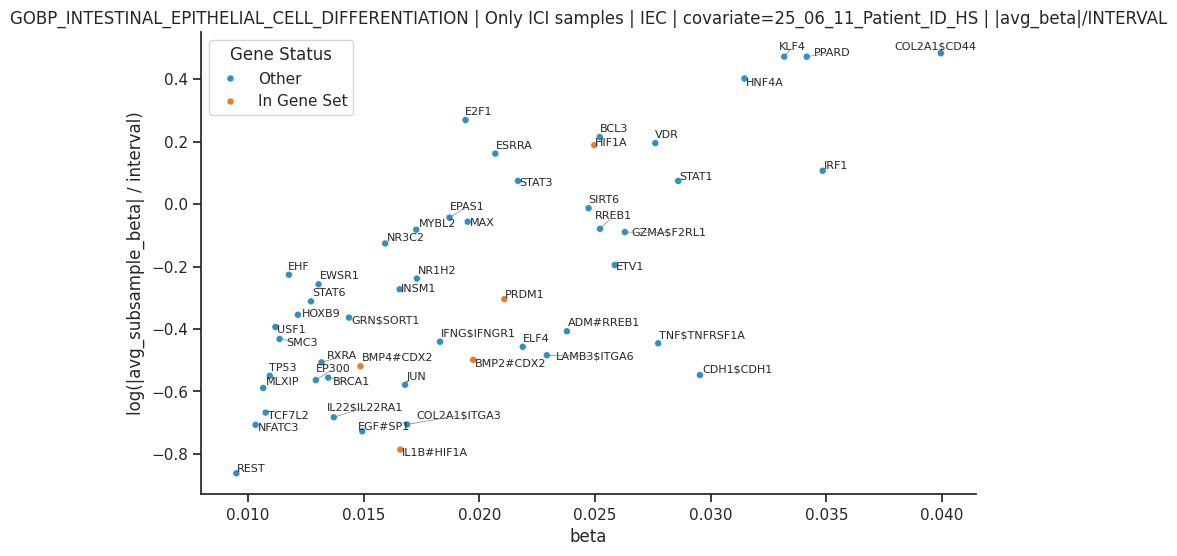

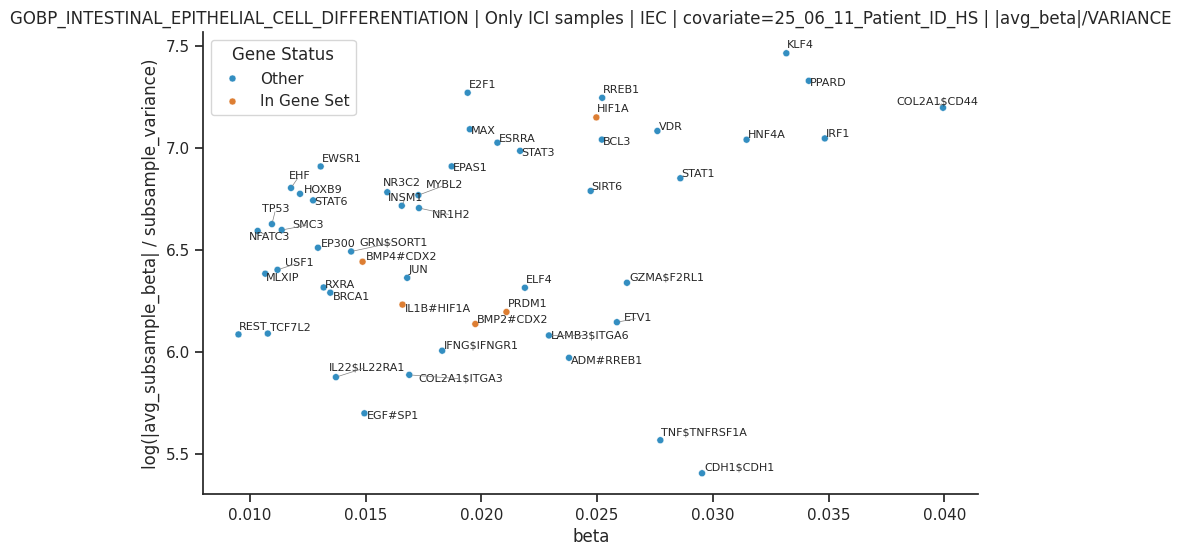

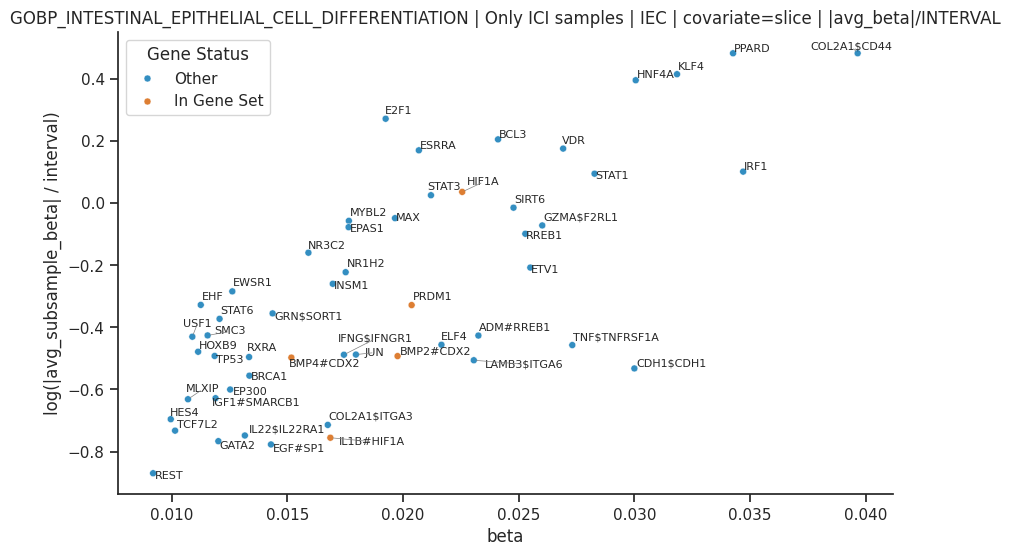

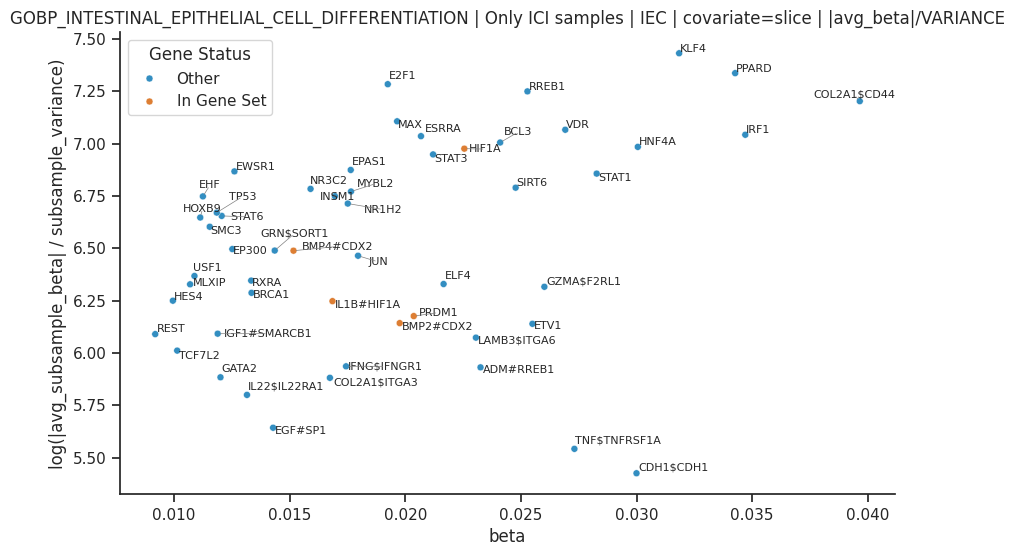

In [7]:
run_colon_signature('GOBP_INTESTINAL_EPITHELIAL_CELL_DIFFERENTIATION')

In [ ]:
run_colon_signature('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

[add_gene_signature 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'] factor_mode='union' keep_when_overlap='factor'
  dropped 56 gene(s) from the target: ['ACKR3', 'ATF3', 'BCL3', 'BCL6', 'BMP2', 'CCL20', 'CD44', 'CD80', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'JAG1', 'JUN', 'KLF4', 'LAMB3', 'LIF', 'MSC', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NR4A1', 'NR4A3', 'REL', 'RELA', 'RELB', 'SDC4', 'SMAD3', 'STAT5A', 'TNC', 'TNF', 'TNFRSF9', 'TNFSF9', 'VEGFA']
  kept all 2713 factor(s)

===== HALLMARK_TNFA_SIGNALING_VIA_NFKB | All colon samples | IEC | covariate=None =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
41,HALLMARK_TNFA_SIGNALING_VIA_NFKB,KLF4,tf,0.164500,0.338419,0.114528,0.608892,110157,0.151253,0.179290,0.162661,0.000041,0.000045,0.157139,0.168452,0.329644,0.349599,0.339866
937,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ADM#RREB1,ltf,0.164284,0.285479,0.081498,0.608892,110157,0.147974,0.202461,0.170766,0.000157,0.000199,0.159182,0.184008,0.255833,0.314227,0.281901
37,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IRF1,tf,0.163454,0.354702,0.125814,0.608892,110157,0.138413,0.178562,0.157496,0.000062,0.000097,0.150805,0.165959,0.346786,0.368644,0.355414
415,HALLMARK_TNFA_SIGNALING_VIA_NFKB,GZMA$F2RL1,lr,0.138168,0.297813,0.088692,0.608892,110157,0.123487,0.157898,0.141570,0.000065,0.000077,0.134510,0.148457,0.280010,0.323186,0.297512
357,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IFNG$IFNGR1,lr,0.130516,0.266975,0.071275,0.608892,110157,0.110272,0.154442,0.134421,0.000097,0.000112,0.126476,0.145132,0.250267,0.290578,0.267830
72,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PRDM1,tf,0.124513,0.218543,0.047761,0.608892,110157,0.100930,0.141598,0.122471,0.000091,0.000095,0.112200,0.131921,0.193076,0.236075,0.220043
1330,HALLMARK_TNFA_SIGNALING_VIA_NFKB,JUN,tf,0.120773,0.259235,0.067203,0.608892,110157,0.099757,0.129277,0.115201,0.000048,0.000079,0.107355,0.122542,0.247535,0.271337,0.260370
1563,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PPARD,tf,0.119997,0.256748,0.065919,0.608892,110157,0.107684,0.136704,0.119925,0.000043,0.000043,0.114132,0.126624,0.248279,0.270130,0.257797
618,HALLMARK_TNFA_SIGNALING_VIA_NFKB,F11R$F11R,lr,0.119461,0.309048,0.095511,0.608892,110157,0.107333,0.149067,0.126158,0.000085,0.000130,0.116527,0.136063,0.283131,0.336089,0.309951
86,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT1,tf,0.115581,0.278857,0.077761,0.608892,110157,0.101341,0.128814,0.113185,0.000042,0.000048,0.106491,0.120169,0.270123,0.289116,0.279790


[add_gene_signature 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'] factor_mode='union' keep_when_overlap='factor'
  dropped 56 gene(s) from the target: ['ACKR3', 'ATF3', 'BCL3', 'BCL6', 'BMP2', 'CCL20', 'CD44', 'CD80', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'JAG1', 'JUN', 'KLF4', 'LAMB3', 'LIF', 'MSC', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NR4A1', 'NR4A3', 'REL', 'RELA', 'RELB', 'SDC4', 'SMAD3', 'STAT5A', 'TNC', 'TNF', 'TNFRSF9', 'TNFSF9', 'VEGFA']
  kept all 2713 factor(s)

===== HALLMARK_TNFA_SIGNALING_VIA_NFKB | All colon samples | IEC | covariate=240927_Condition =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
2714,HALLMARK_TNFA_SIGNALING_VIA_NFKB,240927_Condition[ICI],onehot,0.231767,0.115753,0.013399,0.610234,110157,0.202580,0.249823,0.224884,0.000089,0.000136,0.215963,0.234662,0.108217,0.126157,0.115437
41,HALLMARK_TNFA_SIGNALING_VIA_NFKB,KLF4,tf,0.165827,0.338419,0.114528,0.610234,110157,0.152707,0.180574,0.163828,0.000040,0.000044,0.158467,0.169523,0.329644,0.349599,0.339866
937,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ADM#RREB1,ltf,0.162544,0.285479,0.081498,0.610234,110157,0.145778,0.201661,0.169046,0.000153,0.000196,0.157190,0.181934,0.255833,0.314227,0.281901
37,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IRF1,tf,0.155136,0.354702,0.125814,0.610234,110157,0.131241,0.170227,0.149539,0.000061,0.000092,0.142733,0.158186,0.346786,0.368644,0.355414
415,HALLMARK_TNFA_SIGNALING_VIA_NFKB,GZMA$F2RL1,lr,0.137846,0.297813,0.088692,0.610234,110157,0.122779,0.157855,0.141013,0.000065,0.000075,0.133902,0.147854,0.280010,0.323186,0.297512
357,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IFNG$IFNGR1,lr,0.129493,0.266975,0.071275,0.610234,110157,0.109692,0.154046,0.133741,0.000097,0.000115,0.125620,0.144286,0.250267,0.290578,0.267830
1330,HALLMARK_TNFA_SIGNALING_VIA_NFKB,JUN,tf,0.124948,0.259235,0.067203,0.610234,110157,0.103755,0.133023,0.119376,0.000046,0.000078,0.112376,0.126576,0.247535,0.271337,0.260370
72,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PRDM1,tf,0.124136,0.218543,0.047761,0.610234,110157,0.100477,0.141448,0.122136,0.000091,0.000095,0.111891,0.131370,0.193076,0.236075,0.220043
1563,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PPARD,tf,0.120217,0.256748,0.065919,0.610234,110157,0.108096,0.137617,0.120171,0.000042,0.000042,0.114563,0.126475,0.248279,0.270130,0.257797
618,HALLMARK_TNFA_SIGNALING_VIA_NFKB,F11R$F11R,lr,0.118536,0.309048,0.095511,0.610234,110157,0.106958,0.148503,0.125482,0.000085,0.000134,0.115690,0.135370,0.283131,0.336089,0.309951


[add_gene_signature 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'] factor_mode='union' keep_when_overlap='factor'
  dropped 56 gene(s) from the target: ['ACKR3', 'ATF3', 'BCL3', 'BCL6', 'BMP2', 'CCL20', 'CD44', 'CD80', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'JAG1', 'JUN', 'KLF4', 'LAMB3', 'LIF', 'MSC', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NR4A1', 'NR4A3', 'REL', 'RELA', 'RELB', 'SDC4', 'SMAD3', 'STAT5A', 'TNC', 'TNF', 'TNFRSF9', 'TNFSF9', 'VEGFA']
  kept all 2713 factor(s)

===== HALLMARK_TNFA_SIGNALING_VIA_NFKB | All colon samples | IEC | covariate=25_06_11_Patient_ID_HS =====


...

,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
37,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IRF1,tf,0.217801,0.418217,0.174906,0.72665,32759,0.167050,0.247840,0.207232,0.000200,0.000312,0.194194,0.221578,0.398274,0.434503,0.418518
72,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PRDM1,tf,0.202923,0.301346,0.090809,0.72665,32759,0.149624,0.242018,0.196999,0.000470,0.000505,0.178442,0.221392,0.277826,0.334141,0.301681
937,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ADM#RREB1,ltf,0.198631,0.318143,0.101215,0.72665,32759,0.152742,0.282402,0.218905,0.000765,0.001176,0.191968,0.247234,0.292608,0.350951,0.323320
357,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IFNG$IFNGR1,lr,0.195453,0.346898,0.120338,0.72665,32759,0.170083,0.247535,0.203085,0.000239,0.000297,0.186142,0.216197,0.314076,0.386161,0.347766
415,HALLMARK_TNFA_SIGNALING_VIA_NFKB,GZMA$F2RL1,lr,0.180965,0.329423,0.108520,0.72665,32759,0.153073,0.252205,0.192406,0.000410,0.000541,0.169938,0.209478,0.306866,0.362800,0.329770
41,HALLMARK_TNFA_SIGNALING_VIA_NFKB,KLF4,tf,0.180539,0.345925,0.119664,0.72665,32759,0.139440,0.204863,0.173842,0.000227,0.000272,0.160916,0.187088,0.323384,0.364151,0.345506
86,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT1,tf,0.164563,0.318609,0.101511,0.72665,32759,0.127093,0.189069,0.155980,0.000147,0.000221,0.146642,0.169780,0.309767,0.339552,0.320786
618,HALLMARK_TNFA_SIGNALING_VIA_NFKB,F11R$F11R,lr,0.162049,0.271218,0.073559,0.72665,32759,0.113053,0.238246,0.178395,0.000576,0.000843,0.157519,0.206369,0.239156,0.314894,0.272675
5,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ATF3,tf,0.157925,0.257452,0.066282,0.72665,32759,0.104671,0.194579,0.152474,0.000401,0.000431,0.132565,0.172893,0.224333,0.289828,0.258079
1786,HALLMARK_TNFA_SIGNALING_VIA_NFKB,VDR,tf,0.143041,0.254336,0.064687,0.72665,32759,0.113025,0.178134,0.141075,0.000206,0.000210,0.123941,0.155584,0.238400,0.274461,0.254663


/global/home/users/fosterangus/Projects/MetabTravLR/SpaceTravLR/metab_processing/LinearRegression/signature_helpers.py:180: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  _, ax = plt.subplots(figsize=figsize)


[add_gene_signature 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'] factor_mode='union' keep_when_overlap='factor'
  dropped 56 gene(s) from the target: ['ACKR3', 'ATF3', 'BCL3', 'BCL6', 'BMP2', 'CCL20', 'CD44', 'CD80', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'JAG1', 'JUN', 'KLF4', 'LAMB3', 'LIF', 'MSC', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NR4A1', 'NR4A3', 'REL', 'RELA', 'RELB', 'SDC4', 'SMAD3', 'STAT5A', 'TNC', 'TNF', 'TNFRSF9', 'TNFSF9', 'VEGFA']
  kept all 2713 factor(s)

===== HALLMARK_TNFA_SIGNALING_VIA_NFKB | Only ICI samples | IEC | covariate=25_06_11_Patient_ID_HS =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
2715,HALLMARK_TNFA_SIGNALING_VIA_NFKB,25_06_11_Patient_ID_HS[9553_HS8_ICI],onehot,-0.226955,-0.160051,0.025616,0.727435,32759,-0.275097,-0.167564,-0.219539,0.000822,0.000877,-0.255277,-0.186743,-0.167509,-0.150647,-0.160292
37,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IRF1,tf,0.202246,0.418217,0.174906,0.727435,32759,0.151065,0.232556,0.192236,0.000210,0.000311,0.180133,0.206829,0.398274,0.434503,0.418518
72,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PRDM1,tf,0.201519,0.301346,0.090809,0.727435,32759,0.147528,0.240337,0.195534,0.000469,0.000505,0.176792,0.220204,0.277826,0.334141,0.301681
937,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ADM#RREB1,ltf,0.200817,0.318143,0.101215,0.727435,32759,0.155866,0.280504,0.220047,0.000750,0.001120,0.195243,0.248268,0.292608,0.350951,0.323320
357,HALLMARK_TNFA_SIGNALING_VIA_NFKB,IFNG$IFNGR1,lr,0.192530,0.346898,0.120338,0.727435,32759,0.168179,0.245041,0.201162,0.000235,0.000310,0.184495,0.214319,0.314076,0.386161,0.347766
41,HALLMARK_TNFA_SIGNALING_VIA_NFKB,KLF4,tf,0.186782,0.345925,0.119664,0.727435,32759,0.145876,0.210727,0.180046,0.000222,0.000268,0.166243,0.193264,0.323384,0.364151,0.345506
415,HALLMARK_TNFA_SIGNALING_VIA_NFKB,GZMA$F2RL1,lr,0.178731,0.329423,0.108520,0.727435,32759,0.150878,0.249492,0.189639,0.000413,0.000532,0.166931,0.207144,0.306866,0.362800,0.329770
618,HALLMARK_TNFA_SIGNALING_VIA_NFKB,F11R$F11R,lr,0.167750,0.271218,0.073559,0.727435,32759,0.120542,0.246479,0.185372,0.000597,0.000908,0.165129,0.212719,0.239156,0.314894,0.272675
5,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ATF3,tf,0.157717,0.257452,0.066282,0.727435,32759,0.104414,0.194359,0.152087,0.000404,0.000436,0.131879,0.172345,0.224333,0.289828,0.258079
1563,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PPARD,tf,0.147339,0.300042,0.090025,0.727435,32759,0.106138,0.165618,0.139796,0.000204,0.000261,0.122683,0.155881,0.275434,0.334841,0.299539


[add_gene_signature 'HALLMARK_TNFA_SIGNALING_VIA_NFKB'] factor_mode='union' keep_when_overlap='factor'
  dropped 56 gene(s) from the target: ['ACKR3', 'ATF3', 'BCL3', 'BCL6', 'BMP2', 'CCL20', 'CD44', 'CD80', 'CSF1', 'CSF2', 'CXCL10', 'CXCL11', 'CXCL2', 'CXCL6', 'EDN1', 'EGR2', 'F2RL1', 'FOSL1', 'HBEGF', 'HES1', 'ICAM1', 'ICOSLG', 'IL12B', 'IL15RA', 'IL18', 'IL1A', 'IL1B', 'IL23A', 'IL6', 'IL6ST', 'INHBA', 'IRF1', 'JAG1', 'JUN', 'KLF4', 'LAMB3', 'LIF', 'MSC', 'MYC', 'NFAT5', 'NFE2L2', 'NFKB1', 'NFKB2', 'NR4A1', 'NR4A3', 'REL', 'RELA', 'RELB', 'SDC4', 'SMAD3', 'STAT5A', 'TNC', 'TNF', 'TNFRSF9', 'TNFSF9', 'VEGFA']
  kept all 2713 factor(s)

===== HALLMARK_TNFA_SIGNALING_VIA_NFKB | Only ICI samples | IEC | covariate=slice =====


In [ ]:
run_colon_signature('HALLMARK_INFLAMMATORY_RESPONSE')

In [ ]:
run_colon_signature('HALLMARK_OXIDATIVE_PHOSPHORYLATION')

In [ ]:
run_colon_signature('HALLMARK_GLYCOLYSIS')

In [ ]:
run_colon_signature('HALLMARK_HYPOXIA')

In [ ]:
run_colon_signature('HALLMARK_FATTY_ACID_METABOLISM')

In [ ]:
run_colon_signature('HALLMARK_MTORC1_SIGNALING')

In [ ]:
run_colon_signature('HALLMARK_APICAL_JUNCTION')

In [ ]:
run_colon_signature('HALLMARK_APICAL_SURFACE')

In [ ]:
run_colon_signature('HALLMARK_BILE_ACID_METABOLISM')

In [ ]:
run_colon_signature('HALLMARK_XENOBIOTIC_METABOLISM')

In [ ]:
run_colon_signature('GOBP_BICARBONATE_TRANSPORT')

In [ ]:
run_colon_signature('GOBP_SODIUM_ION_TRANSPORT')

In [ ]:
run_colon_signature('GOBP_DEFENSE_RESPONSE_TO_BACTERIUM')

In [ ]:
run_colon_signature('GOBP_ANTIMICROBIAL_HUMORAL_RESPONSE')

In [ ]:
run_colon_signature('HALLMARK_PANCREAS_BETA_CELLS')

In [ ]:
run_colon_signature('HALLMARK_SPERMATOGENESIS')